# تمرین اول – preprocessing 


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from IPython.display import display 
import re



## بخش ۱ :
### بررسی اولیه دیتاست شامل ساختار کلی ستو نها 

In [45]:
# Load Dataset
df = pd.read_csv('HeartDisease_dirty.csv')
df.columns = [c.strip() for c in df.columns]
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())




Dataset Shape: (338397, 21)
Columns: ['RecordID', 'HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke', 'physical_health', 'MentalHealth', 'DiffWalking', 'Sex', 'AgeCategory', 'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'Sleep Time', 'Asthma', 'KidneyDisease', 'SkinCancer', 'SurveyYear', 'Comments']


In [46]:
# بررسی ساختار و نوع داده‌ها
print("--- اطلاعات کلی دیتاست ---")
print(df.info())


--- اطلاعات کلی دیتاست ---
<class 'pandas.DataFrame'>
RangeIndex: 338397 entries, 0 to 338396
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   RecordID          338397 non-null  str  
 1   HeartDisease      306781 non-null  str  
 2   BMI               303966 non-null  str  
 3   Smoking           331687 non-null  str  
 4   AlcoholDrinking   310375 non-null  str  
 5   Stroke            313041 non-null  str  
 6   physical_health   321857 non-null  str  
 7   MentalHealth      301630 non-null  str  
 8   DiffWalking       322418 non-null  str  
 9   Sex               338397 non-null  str  
 10  AgeCategory       319777 non-null  str  
 11  Race              309807 non-null  str  
 12  Diabetic          336126 non-null  str  
 13  PhysicalActivity  313922 non-null  str  
 14  GenHealth         321832 non-null  str  
 15  Sleep Time        322007 non-null  str  
 16  Asthma            309994 non-null  str  

###  استخراج آمار توصیفی اولیه از هر ستون

In [47]:

# Basic Statistics & Descriptive Analysis
print(df.describe(include='all'))


       RecordID HeartDisease     BMI Smoking AlcoholDrinking  Stroke  \
count    338397       306781  303966  331687          310375  313041   
unique   318169           53   17702     325             320     234   
top     P036879           No       ?      No              No      No   
freq          5       267007    5543  188693          244076  285275   

       physical_health MentalHealth DiffWalking     Sex  ...    Race Diabetic  \
count           321857       301630      322418  338397  ...  309807   336126   
unique             199          237         129     686  ...     266      443   
top                  0            0          No  Female  ...   White       No   
freq            211648       176322      228884  143583  ...  190698   256433   

       PhysicalActivity  GenHealth Sleep Time  Asthma KidneyDisease  \
count            313922     321832     322007  309994        317204   
unique              183        313        178     340           248   
top                 

In [48]:
#   Column Categories 
SymmetricBinaryCols = ['Sex']
AsymmetricBinaryCols = ['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 
                        'DiffWalking', 'Diabetic', 'PhysicalActivity', 'Asthma', 
                        'KidneyDisease', 'SkinCancer']
NominalCols = ['Race', 'Comments']
OrdinalCols = ['AgeCategory', 'GenHealth']
IDCols = ['RecordID']
NumericCols = ['BMI', 'physical_health', 'MentalHealth', 'Sleep Time', 'SurveyYear']
#TextCols = ['Comments']


### تجسم داده ها شامل رسم نمودارهای هیستوگرام و باکسپلات

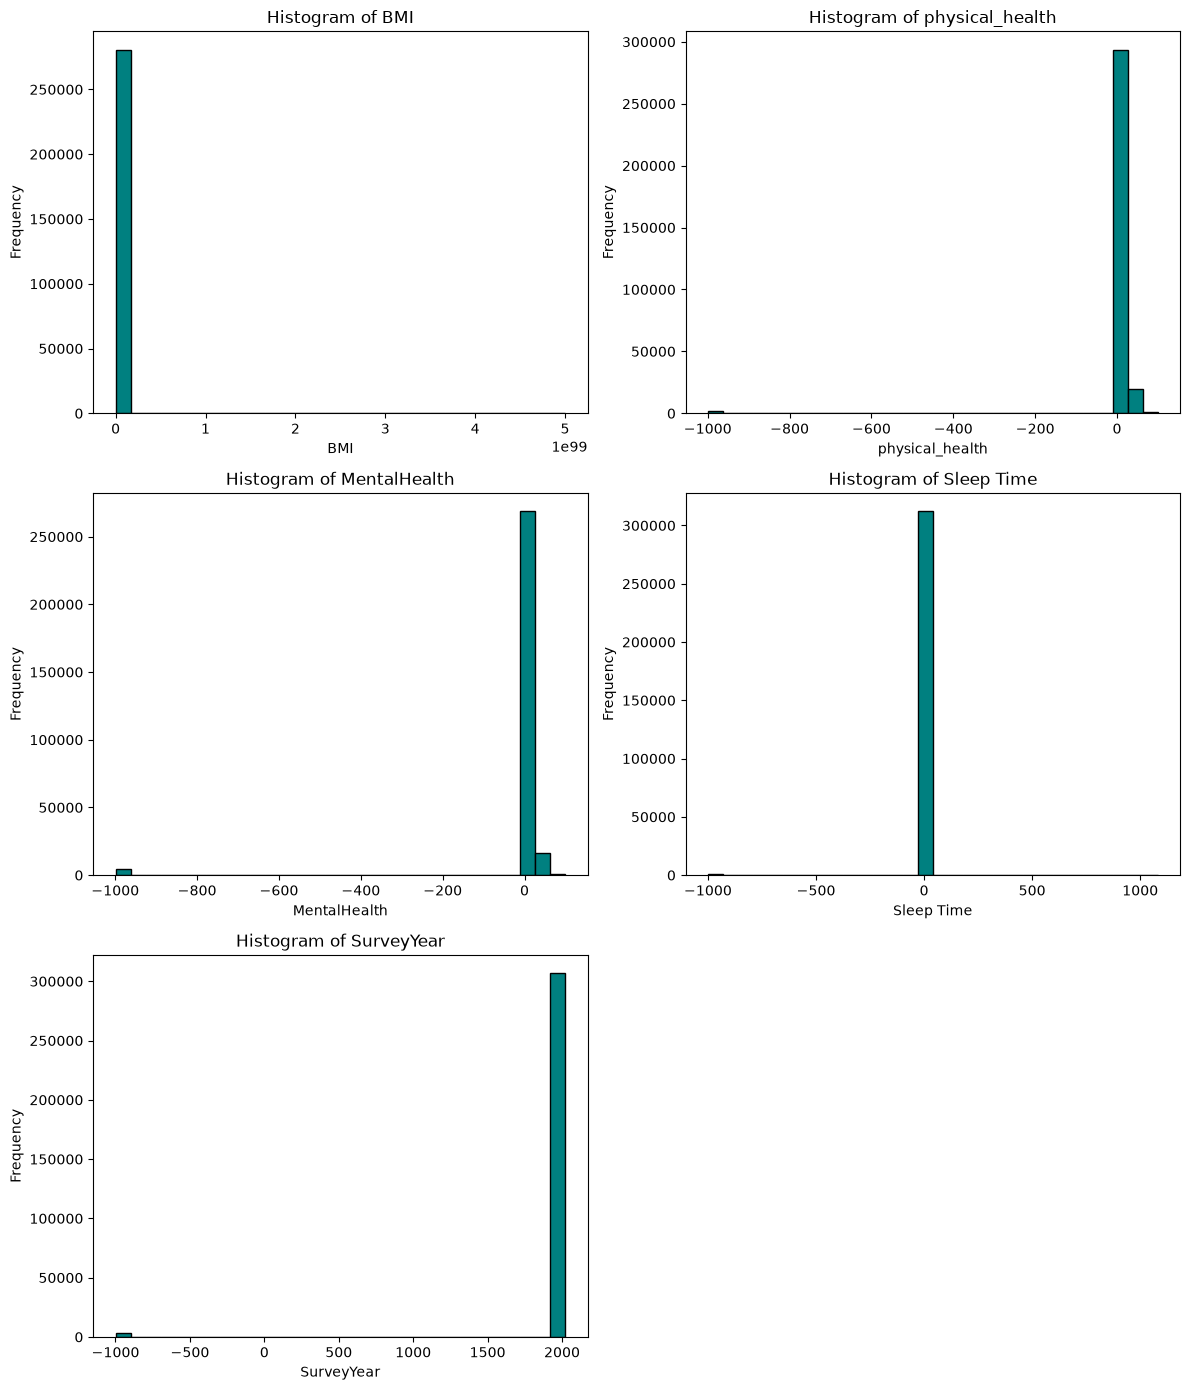

In [49]:
#  Histograms for Numeric Columns
for col in NumericCols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

#  تنظیم شبکه ۳ در ۲ برای ۵ ستون عددی
fig, axes = plt.subplots(3, 2, figsize=(12, 14))
axes = axes.flatten()  # برای دسترسی راحت‌تر به شکل یک آرایه یک‌بعدی

for i, col in enumerate(NumericCols):
    ax = axes[i]
    data_clean = df[col].dropna()
    
    ax.hist(data_clean, bins=30, color='teal', edgecolor='black')
    ax.set_title(f'Histogram of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

# حذف پلات اضافی (چون شبکه ۳ در ۲ یعنی ۶ خانه داریم اما ۵ ستون داریم)
if len(NumericCols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


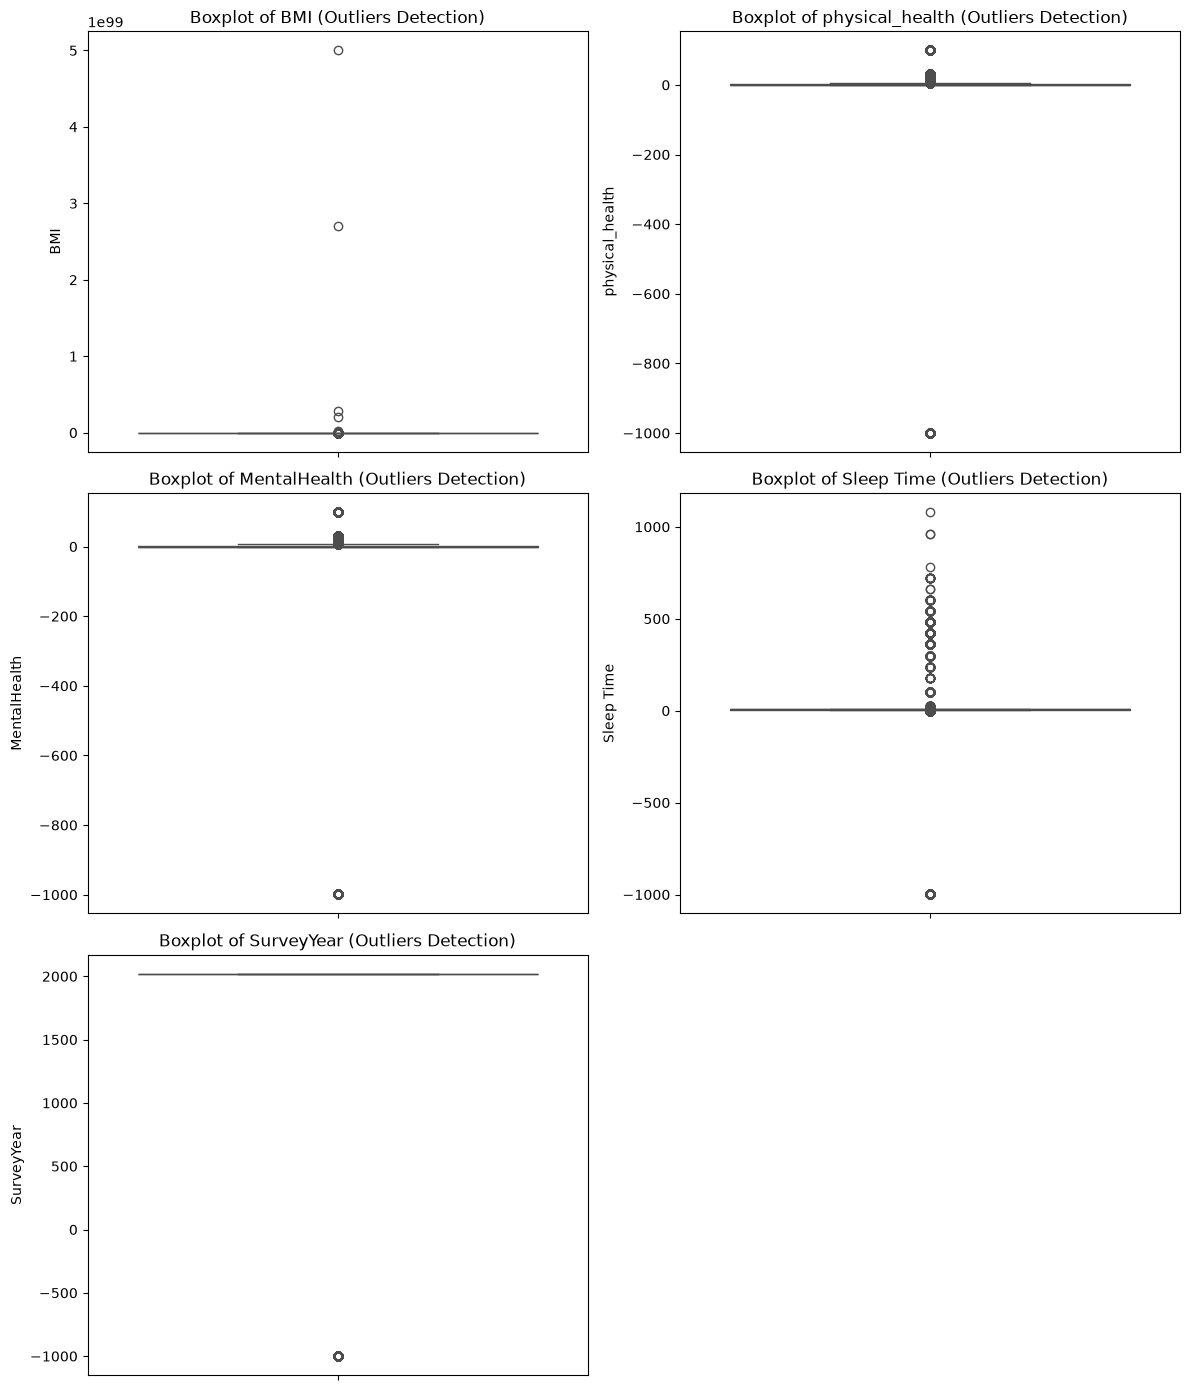

In [50]:

#  Boxplots for Numeric Columns (Outlier detection visual)
# تنظیم شبکه ۳ در ۲ برای باکس‌پلات‌ها
fig, axes = plt.subplots(3, 2, figsize=(12, 14))
axes = axes.flatten()

for i, col in enumerate(NumericCols):
    ax = axes[i]
    data_clean = df[col].dropna()
    
    sns.boxplot(y=data_clean, ax=ax, color='orange')
    ax.set_title(f'Boxplot of {col} (Outliers Detection)')
    ax.set_ylabel(col)

if len(NumericCols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

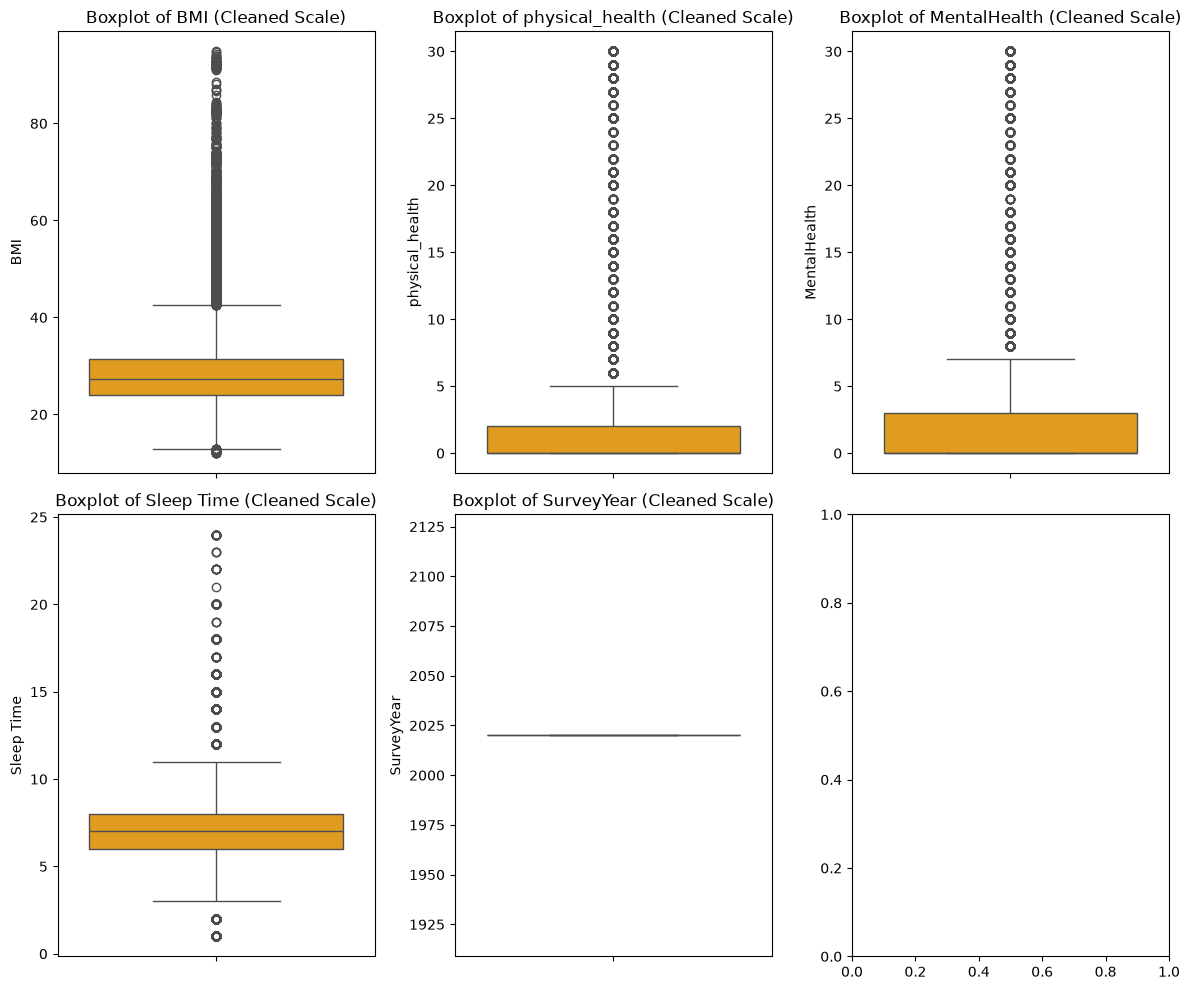

In [51]:
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(NumericCols):
    ax = axes[i]
    # حذف مقادیر پرت شدید و نویزهای مثل -999 یا مقادیر ناممکن برای نمایش واضح‌تر جعبه
    data_clean = df[col].dropna()
    if col == 'BMI':
        data_clean = data_clean[(data_clean > 10) & (data_clean < 100)]
    elif col in ['physical_health', 'MentalHealth']:
        data_clean = data_clean[(data_clean >= 0) & (data_clean <= 30)]
    elif col == 'Sleep Time':
        data_clean = data_clean[(data_clean > 0) & (data_clean <= 24)]
    elif col == 'SurveyYear'   : 
        data_clean = data_clean[(data_clean > 2000 ) & (data_clean < 2027 )]
    sns.boxplot(y=data_clean, ax=ax, color='orange')
    ax.set_title(f'Boxplot of {col} (Cleaned Scale)')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()


📊 Frequency Table for: Sex


,Value,Count,Percentage (%)
0,Female,143583,42.43
1,Male,129942,38.40
2,FEMALE,5132,1.52
3,female,5049,1.49
4,MALE,4753,1.40
...,...,...,...
681,Femlae,1,0.00
682,r Male,1,0.00
683,mAsLE,1,0.00
684,qFemale,1,0.00


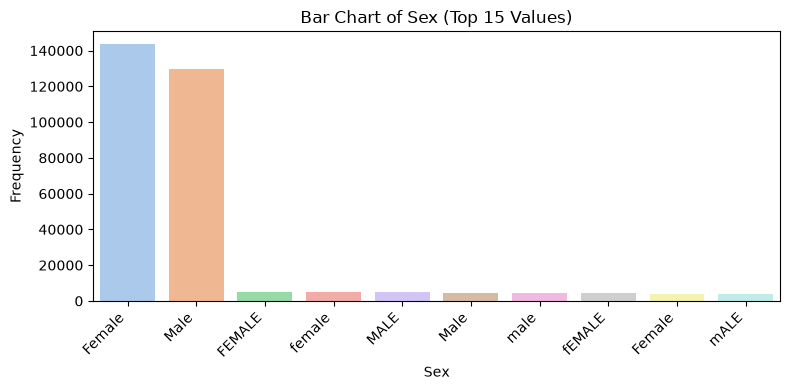


📊 Frequency Table for: HeartDisease


,Value,Count,Percentage (%)
0,No,267007,78.90
1,NaN,31616,9.34
2,Yes,24904,7.36
3,none,4552,1.35
4,?,4458,1.32
5,-999,4363,1.29
6,no,356,0.11
7,No,346,0.10
8,No,326,0.10
9,NO,296,0.09


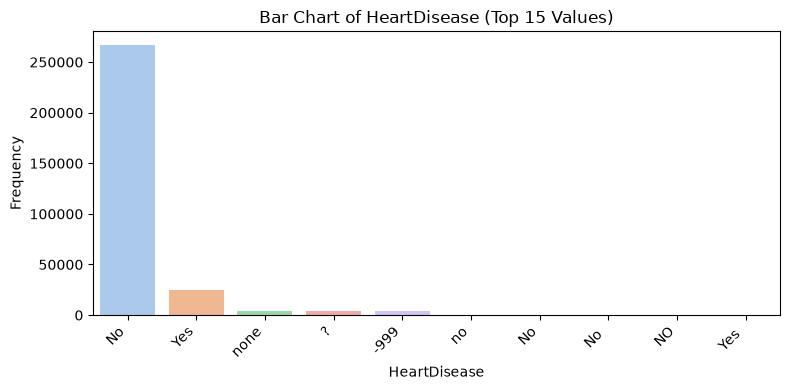


📊 Frequency Table for: Smoking


,Value,Count,Percentage (%)
0,No,188693,55.76
1,Yes,121220,35.82
2,NaN,6710,1.98
3,?,1750,0.52
4,unknown,1562,0.46
...,...,...,...
321,vo,1,0.00
322,wnknown,1,0.00
323,unknofn,1,0.00
324,YYwes,1,0.00


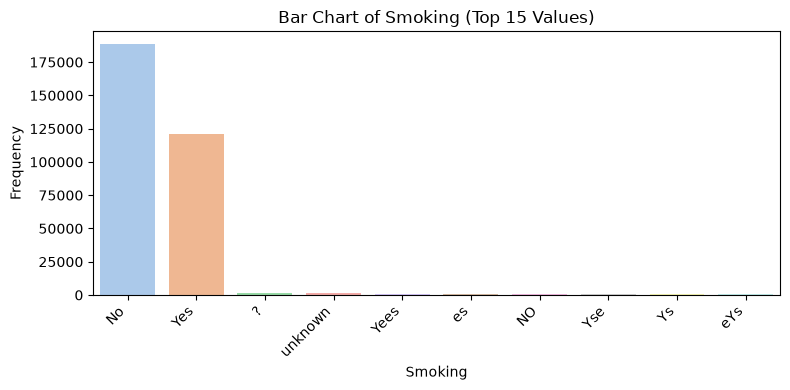


📊 Frequency Table for: AlcoholDrinking


,Value,Count,Percentage (%)
0,No,244076,72.13
1,NaN,28022,8.28
2,Yes,16418,4.85
3,no,6471,1.91
4,No,6382,1.89
...,...,...,...
316,YES,1,0.00
317,ao,1,0.00
318,1,1,0.00
319,e No,1,0.00


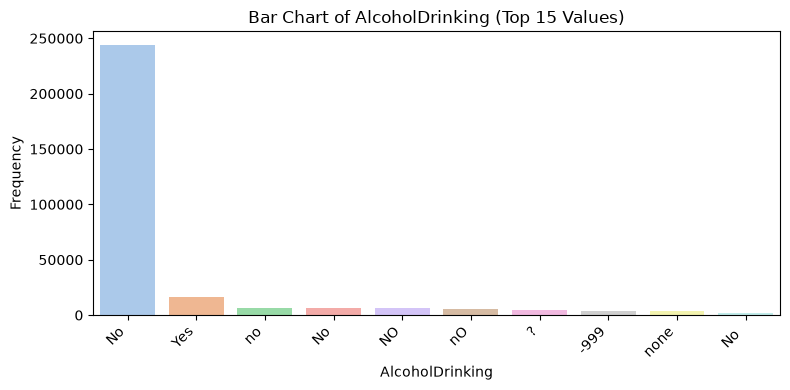


📊 Frequency Table for: Stroke


,Value,Count,Percentage (%)
0,No,285275,84.30
1,NaN,25356,7.49
2,Yes,10125,2.99
3,-999,3559,1.05
4,none,3513,1.04
...,...,...,...
230,pYes,1,0.00
231,lo,1,0.00
232,cNo,1,0.00
233,nes,1,0.00


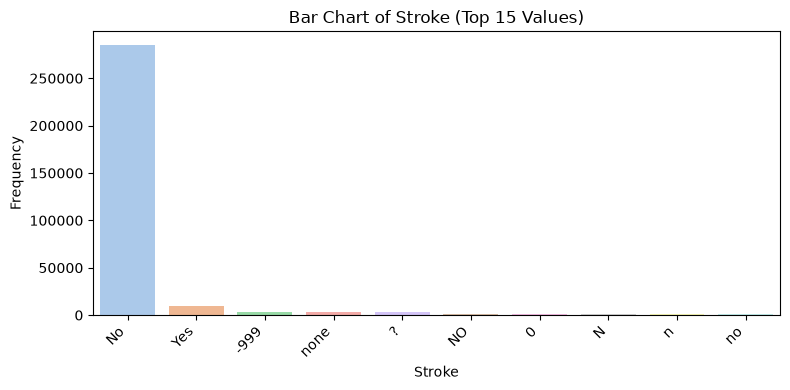


📊 Frequency Table for: DiffWalking


,Value,Count,Percentage (%)
0,No,228884,67.64
1,Yes,36846,10.89
2,NaN,15979,4.72
3,No,8328,2.46
4,NO,8157,2.41
...,...,...,...
125,oYes,1,0.00
126,-z99,1,0.00
127,Nmo,1,0.00
128,1,1,0.00


C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\3293428498.py:31: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


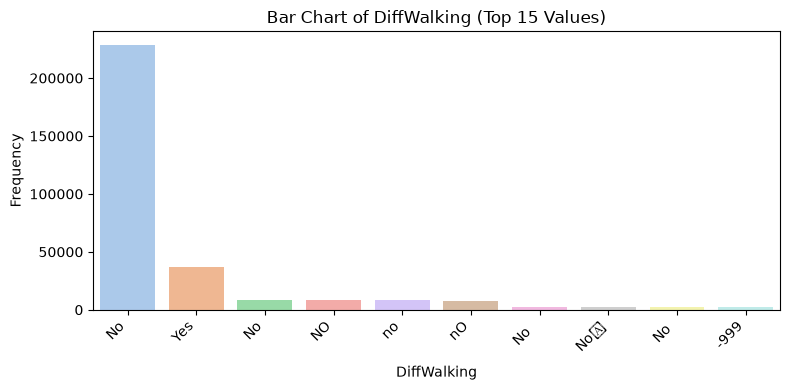


📊 Frequency Table for: Diabetic


,Value,Count,Percentage (%)
0,No,256433,75.78
1,Yes,37571,11.10
2,no,6756,2.00
3,"No, borderline diabetes",6255,1.85
4,NO,4206,1.24
...,...,...,...
439,"No, borderline diabdtes",1,0.00
440,"No, borderline ddiabetes",1,0.00
441,"No, borderline ndiabetes",1,0.00
442,"No, nborderline diabetes",1,0.00


C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\3293428498.py:31: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


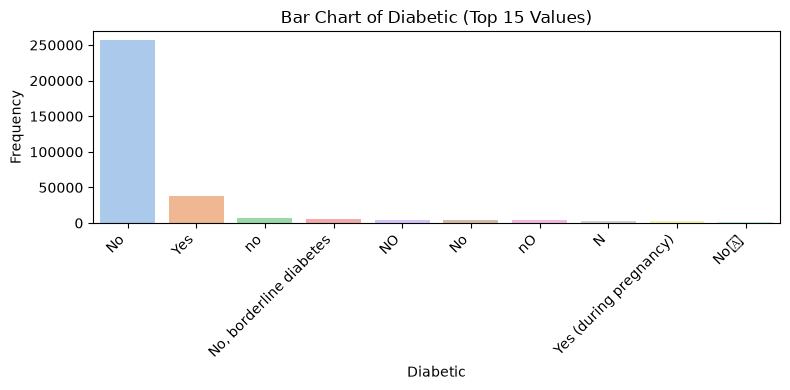


📊 Frequency Table for: PhysicalActivity


,Value,Count,Percentage (%)
0,Yes,202325,59.79
1,No,58728,17.35
2,NaN,24475,7.23
3,yes,6232,1.84
4,Yes,6223,1.84
...,...,...,...
179,Yys,1,0.00
180,NO\t,1,0.00
181,NA/,1,0.00
182,NcA,1,0.00


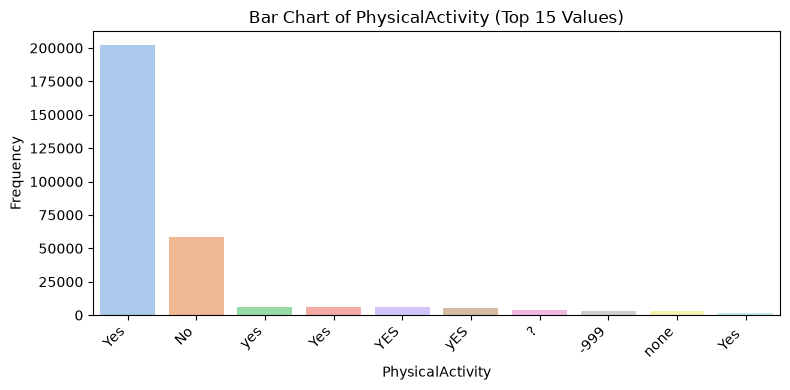


📊 Frequency Table for: Asthma


,Value,Count,Percentage (%)
0,No,212657,62.84
1,Yes,30955,9.15
2,NaN,28403,8.39
3,no,8615,2.55
4,No,8515,2.52
...,...,...,...
336,unknpown,1,0.00
337,Nzo,1,0.00
338,YSE,1,0.00
339,yES,1,0.00


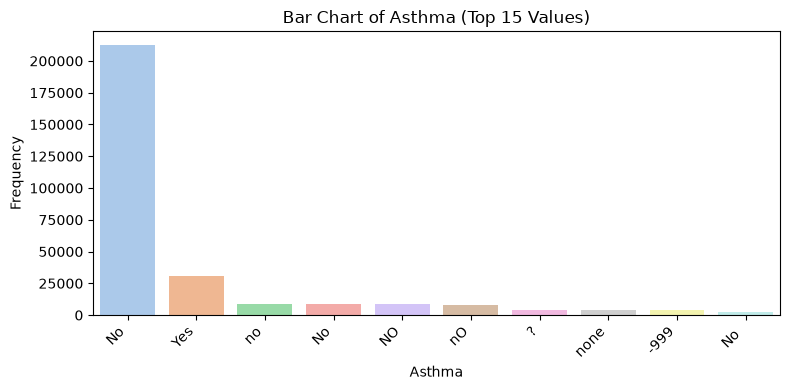


📊 Frequency Table for: KidneyDisease


,Value,Count,Percentage (%)
0,No,264679,78.22
1,NaN,21193,6.26
2,Yes,9573,2.83
3,NO,6102,1.80
4,No,5924,1.75
...,...,...,...
244,1\t,1,0.00
245,eNo,1,0.00
246,Yves,1,0.00
247,uYes,1,0.00


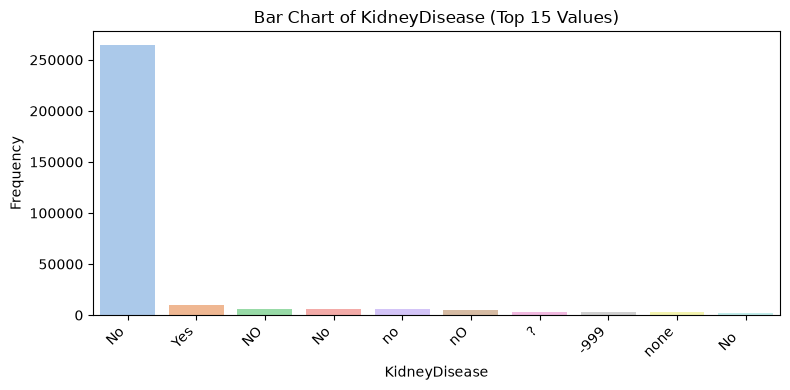


📊 Frequency Table for: SkinCancer


,Value,Count,Percentage (%)
0,No,280249,82.82
1,Yes,26332,7.78
2,no,4980,1.47
3,NO,4972,1.47
4,No,4736,1.40
...,...,...,...
277,yNo,1,0.00
278,gES,1,0.00
279,Nwo,1,0.00
280,sNo,1,0.00


C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\3293428498.py:31: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


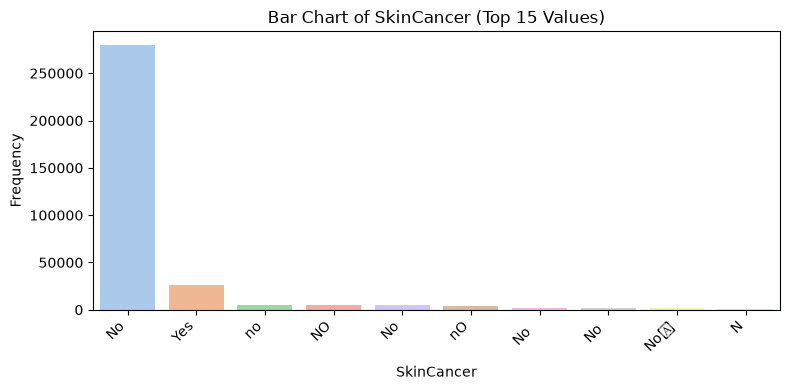


📊 Frequency Table for: Race


,Value,Count,Percentage (%)
0,White,190698,56.35
1,NaN,28590,8.45
2,Hispanic,21241,6.28
3,Black,17832,5.27
4,Other,8463,2.50
...,...,...,...
262,Oter,1,0.00
263,WWHITE,1,0.00
264,Hspanic,1,0.00
265,mWhite,1,0.00


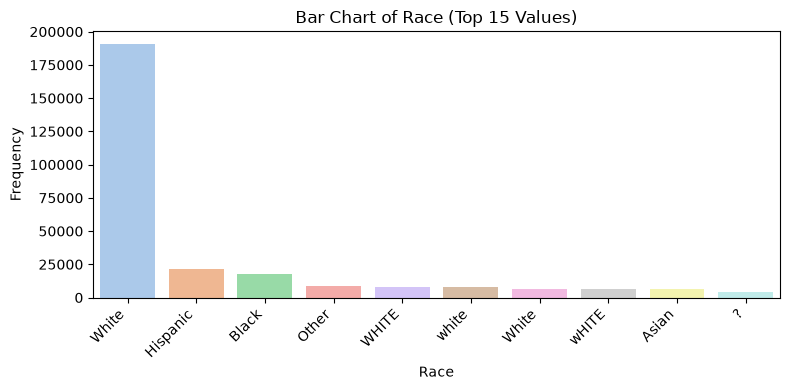


📊 Frequency Table for: Comments


,Value,Count,Percentage (%)
0,NaN,333497,98.55
1,ok,852,0.25
2,phone survey,852,0.25
3,incomplete call,841,0.25
4,follow up,793,0.23
5,re-contacted,767,0.23
6,-999,269,0.08
7,none,268,0.08
8,?,255,0.08
9,NUpL,1,0.00


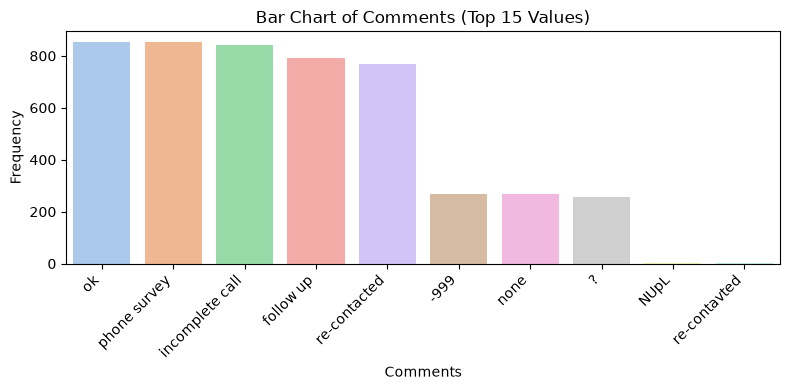


📊 Frequency Table for: AgeCategory


,Value,Count,Percentage (%)
0,65-69,30725,9.08
1,60-64,30551,9.03
2,70-74,28020,8.28
3,55-59,26853,7.94
4,50-54,22960,6.78
...,...,...,...
491,80 oo older,1,0.00
492,30-43,1,0.00
493,60to64,1,0.00
494,65to69,1,0.00


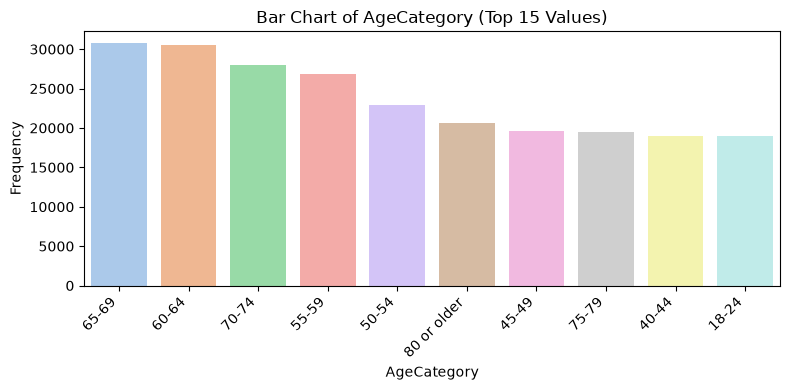


📊 Frequency Table for: GenHealth


,Value,Count,Percentage (%)
0,Very good,102158,30.19
1,Good,83488,24.67
2,Excellent,59856,17.69
3,Fair,31167,9.21
4,NaN,16565,4.90
...,...,...,...
309,Veryqgood,1,0.00
310,Farr,1,0.00
311,vEiY GOOD,1,0.00
312,lery good,1,0.00


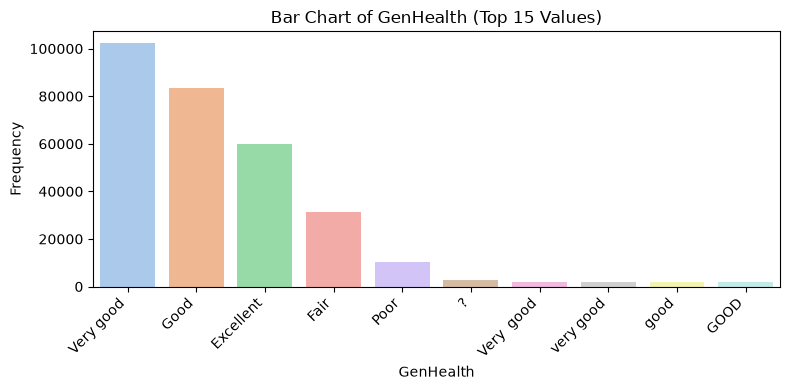

In [52]:

# ترکیب همه متغیرهای دسته‌ای در یک لیست برای پیمایش راحت‌تر
all_categorical_cols = SymmetricBinaryCols + AsymmetricBinaryCols + NominalCols + OrdinalCols

for col in all_categorical_cols:

    # ساخت جدول فراوانی
    # value_counts مقادیر را می‌شمارد، reset_index آن را به دیتافریم تبدیل می‌کند
    counts_df = df[col].value_counts(dropna=False).reset_index()
    counts_df.columns = ['Value', 'Count']
    
    # محاسبه درصد فراوانی
    counts_df['Percentage (%)'] = (counts_df['Count'] / len(df)) * 100
    counts_df['Percentage (%)'] = counts_df['Percentage (%)'].round(2) # گرد کردن به ۲ رقم اعشار
    
    print(f"\n{'='*40}")
    print(f"📊 Frequency Table for: {col}")
    print(f"{'='*40}")
    # نمایش جدول
    display(counts_df)
    
    #  رسم نمودار میله‌ای (برای جلوگیری از شلوغی، فقط ۱۵ دسته اول را رسم می‌کنیم)
    plt.figure(figsize=(8, 4))
    
    # گرفتن ۱۵ مقدار پرتکرار برای رسم نمودار
    plot_data = df[col].value_counts().head(10)
    
    sns.barplot(x=plot_data.index, y=plot_data.values, hue=plot_data.index, palette='pastel', legend=False)
    plt.title(f'Bar Chart of {col} (Top 15 Values)')
    plt.ylabel('Frequency')
    plt.xticks(rotation=45, ha='right') # چرخاندن متن محور X
    plt.tight_layout()
    plt.show()

### شناسایی و مستندسازی داد ههای پرت، نویز و مقادیر گمشده ) missing values ( با رو ش مناسب.

In [53]:
# Missing Values Analysis

missing_info = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_info = missing_info.sort_values(
    by='Missing Percentage',
    ascending=False
)

print("--- Missing Values Report ---")
display(missing_info.round(2))

# بررسی  کاراکترهای نامعتبر (مانند -999 یا ?)
for col in df.columns:
    noise_count = df[df[col].astype(str).str.contains(r'\?|\-999|none|unknown', case=False, na=False)].shape[0]
    if noise_count > 0:
        print(f"Column '{col}' has {noise_count} invalid entries.")

--- Missing Values Report ---


,Missing Count,Missing Percentage
Comments,333497,98.55
BMI,57619,17.03
MentalHealth,47912,14.16
HeartDisease,31616,9.34
Race,28590,8.45
SurveyYear,28481,8.42
Asthma,28403,8.39
AlcoholDrinking,28022,8.28
Stroke,25356,7.49
PhysicalActivity,24475,7.23


Column 'HeartDisease' has 13375 invalid entries.
Column 'BMI' has 3582 invalid entries.
Column 'Smoking' has 3319 invalid entries.
Column 'AlcoholDrinking' has 12165 invalid entries.
Column 'Stroke' has 10545 invalid entries.
Column 'physical_health' has 1711 invalid entries.
Column 'MentalHealth' has 4650 invalid entries.
Column 'DiffWalking' has 6926 invalid entries.
Column 'AgeCategory' has 8036 invalid entries.
Column 'Race' has 12197 invalid entries.
Column 'Diabetic' has 1102 invalid entries.
Column 'PhysicalActivity' has 10522 invalid entries.
Column 'GenHealth' has 7441 invalid entries.
Column 'Sleep Time' has 1319 invalid entries.
Column 'Asthma' has 12569 invalid entries.
Column 'KidneyDisease' has 9038 invalid entries.
Column 'SurveyYear' has 3056 invalid entries.
Column 'Comments' has 792 invalid entries.


In [54]:
# Domain-based validation

invalid_counts = {}

for col in NumericCols:
    if col == 'BMI':
        invalid = (df[col] <= 0) | (df[col] > 100)

    elif col in ['physical_health', 'MentalHealth']:
        invalid = (df[col] < 0) | (df[col] > 30)

    elif col == 'Sleep Time':
        invalid = (df[col] <= 0) | (df[col] > 24)

    elif col == 'SurveyYear':
        invalid = (df[col] < 2000) | (df[col] > 2026)

    invalid_counts[col] = invalid.sum()

print("--- Invalid Numeric Values ---")
print(pd.Series(invalid_counts, name='Invalid Count'))

--- Invalid Numeric Values ---
BMI                6650
physical_health    3287
MentalHealth       6075
Sleep Time         3187
SurveyYear         3056
Name: Invalid Count, dtype: int64


روش مقابله با داده‌های پرت (Outliers) با استفاده از معیار IQR

In [55]:
# Outlier Detection using IQR method (Boxplot stats)

for col in NumericCols:
    series = df[col].dropna()
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    print(f"متغیر {col}: تعداد داده‌های پرت شناسایی شده = {len(outliers)} (حد پایین: {lower_bound:.2f}, حد بالا: {upper_bound:.2f})")

متغیر BMI: تعداد داده‌های پرت شناسایی شده = 16179 (حد پایین: 12.02, حد بالا: 43.30)
متغیر physical_health: تعداد داده‌های پرت شناسایی شده = 48769 (حد پایین: -3.00, حد بالا: 5.00)
متغیر MentalHealth: تعداد داده‌های پرت شناسایی شده = 51177 (حد پایین: -4.50, حد بالا: 7.50)
متغیر Sleep Time: تعداد داده‌های پرت شناسایی شده = 7631 (حد پایین: 3.00, حد بالا: 11.00)
متغیر SurveyYear: تعداد داده‌های پرت شناسایی شده = 3056 (حد پایین: 2020.00, حد بالا: 2020.00)


الف) ماتریس همبستگی (Correlation Matrix) برای متغیرهای عددی:

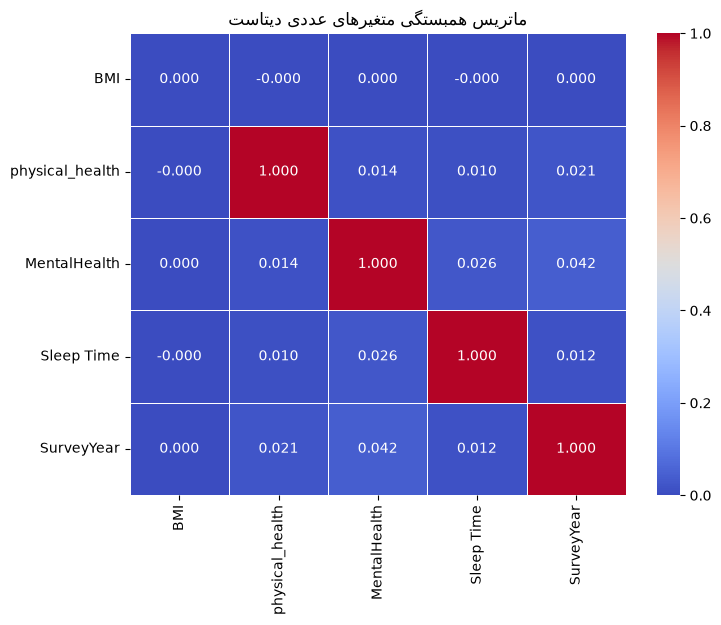

In [56]:
#  Correlation Matrix and Heatmap
plt.figure(figsize=(8, 6))
numeric_subset = df[NumericCols].dropna()
corr_matrix = numeric_subset.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5)
plt.title("ماتریس همبستگی متغیرهای عددی دیتاست")
plt.show()

ب) نمودارهای پراکنش (Scatter Plots) برای بررسی روابط دو‌متغیره:

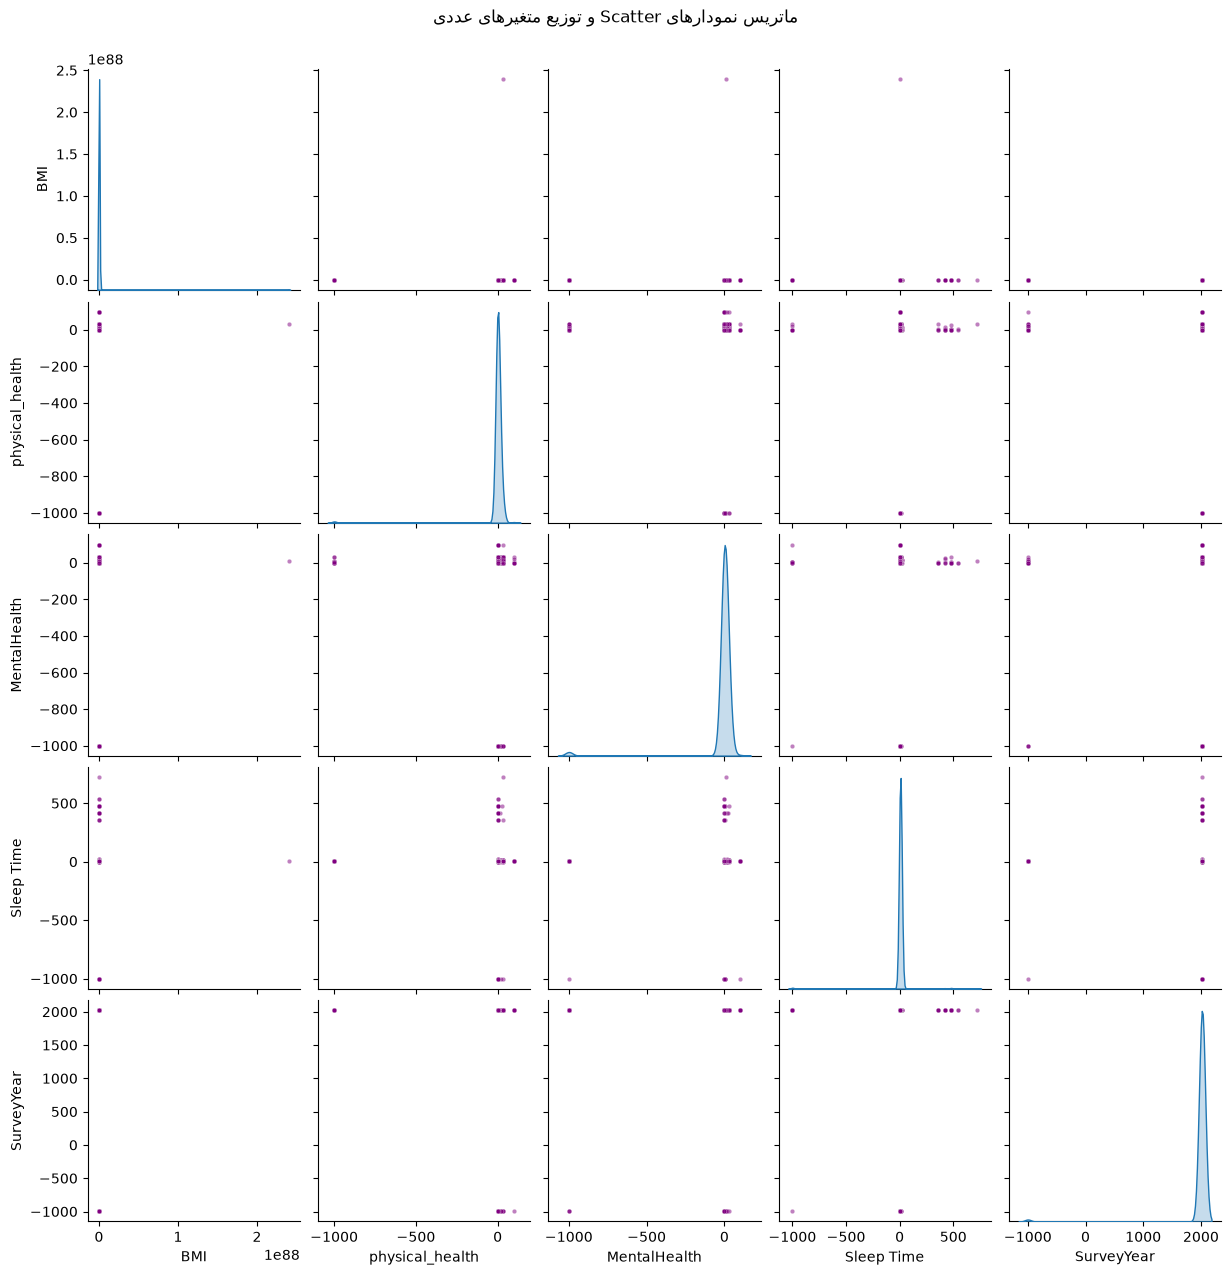

In [57]:
# نمونه‌برداری ۵۰۰۰ سطر برای سرعت بالاتر و رسم نمودار با plot_kws
sample_df = df[NumericCols].sample(n=min(5000, len(df[NumericCols])), random_state=42)

sns.pairplot(
    sample_df[NumericCols], 
    diag_kind='kde', 
    plot_kws={'alpha': 0.5, 'color': 'purple', 's': 10}
)
plt.suptitle("ماتریس نمودارهای Scatter و توزیع متغیرهای عددی", y=1.02)
plt.show()

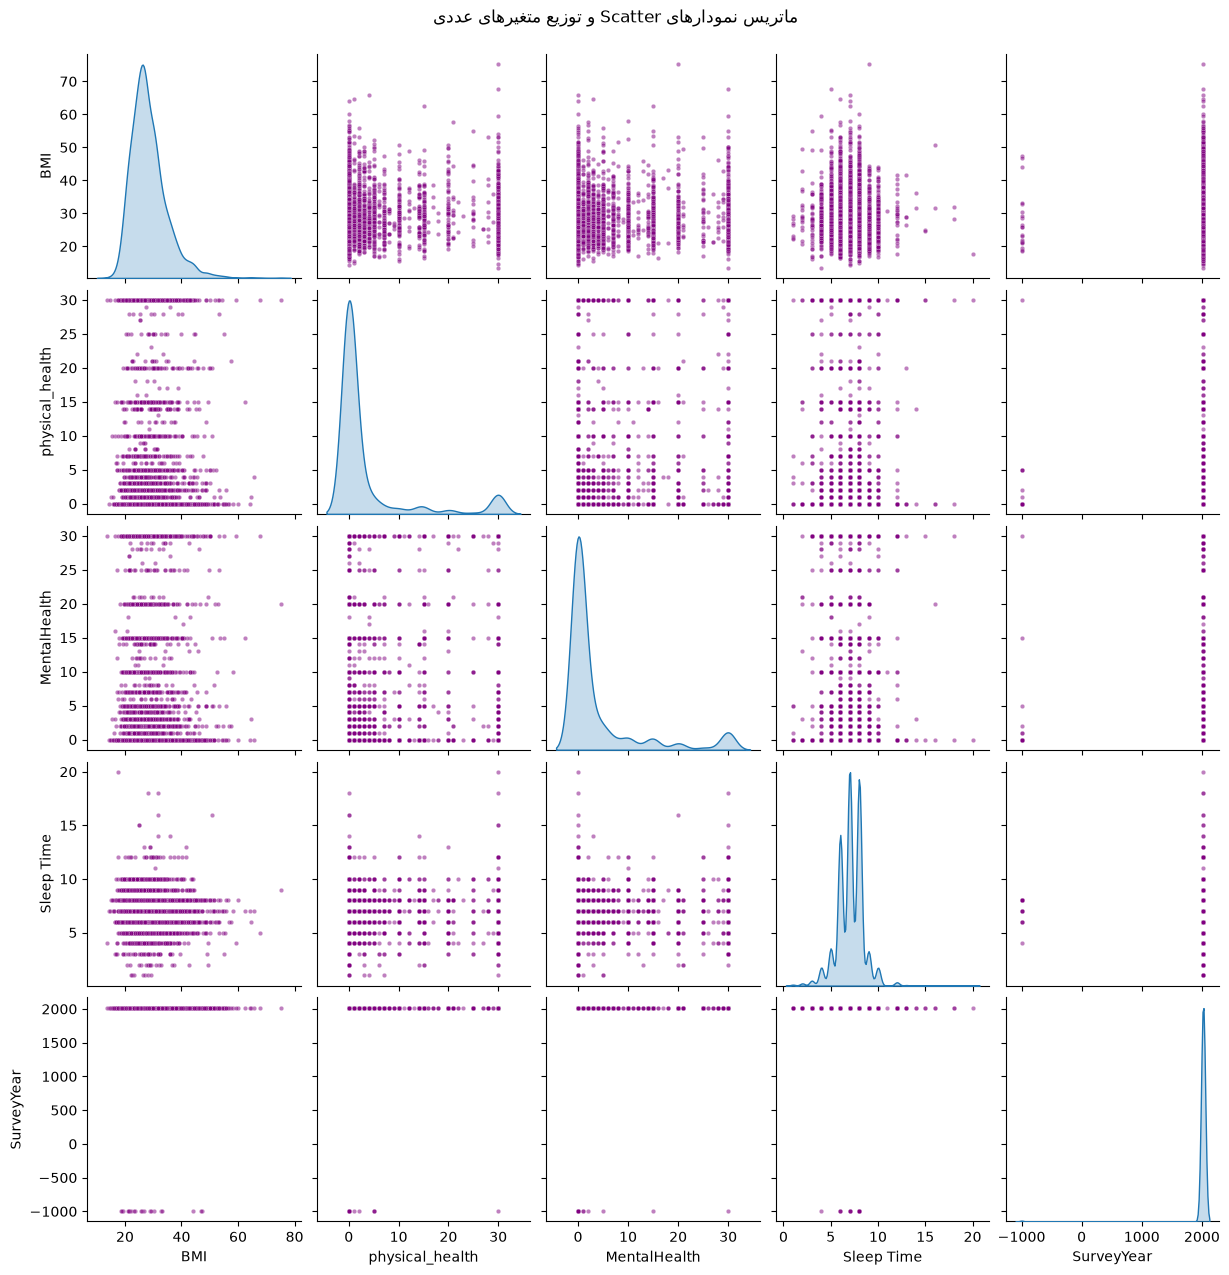

In [58]:
#  فیلتر کردن مقادیر نویز و پرت شدید برای خوانایی بهتر نمودار
df_clean_scatter = df.dropna(subset=NumericCols).copy()
df_clean_scatter = df_clean_scatter[
    (df_clean_scatter['BMI'] > 10) & (df_clean_scatter['BMI'] < 100) &
    (df_clean_scatter['physical_health'] >= 0) & (df_clean_scatter['physical_health'] <= 30) &
    (df_clean_scatter['MentalHealth'] >= 0) & (df_clean_scatter['MentalHealth'] <= 30) &
    (df_clean_scatter['Sleep Time'] > 0) & (df_clean_scatter['Sleep Time'] <= 24)
]

#  نمونه‌برداری ۵۰۰۰ سطر برای سرعت بالاتر و رسم نمودار با plot_kws
sample_df = df_clean_scatter.sample(n=min(5000, len(df_clean_scatter)), random_state=42)

sns.pairplot(
    sample_df[NumericCols], 
    diag_kind='kde', 
    plot_kws={'alpha': 0.5, 'color': 'purple', 's': 10}
)
plt.suptitle("ماتریس نمودارهای Scatter و توزیع متغیرهای عددی", y=1.02)
plt.show()

## بخش 2
in the doc

In [59]:
# Possible representations of missing values
missing_tokens = [
    '', 'null', 'none', 'n/a', 'na',
    'unknown', '?'
]

# Special invalid codes
special_invalid_tokens = ['-999']

# Expected values for categorical columns
expected_categories = {
    'Sex': ['male', 'female'],

    'HeartDisease': ['yes', 'no'],
    'Smoking': ['yes', 'no'],
    'AlcoholDrinking': ['yes', 'no'],
    'Stroke': ['yes', 'no'],
    'DiffWalking': ['yes', 'no'],
    'PhysicalActivity': ['yes', 'no'],
    'Asthma': ['yes', 'no'],
    'KidneyDisease': ['yes', 'no'],
    'SkinCancer': ['yes', 'no'],

    'Diabetic': [
        'yes', 'no',
        'no, borderline diabetes',
        'yes (during pregnancy)'
    ],

    'Race': [
        'white',
        'black',
        'asian',
        'hispanic',
        'other',
        'american indian/alaskan native'
    ],

    'GenHealth': [
        'excellent',
        'very good',
        'good',
        'fair',
        'poor'
    ],

    'AgeCategory': [
        '18-24', '25-29', '30-34', '35-39',
        '40-44', '45-49', '50-54', '55-59',
        '60-64', '65-69', '70-74', '75-79',
        '80 or older'
    ]
}

CategoricalCols = (
    SymmetricBinaryCols +
    AsymmetricBinaryCols +
    NominalCols +
    OrdinalCols
)

ساخت گزارش جامع برای تمام ستون‌ها

In [60]:
# Comprehensive Column Quality Report

report = []

for col in df.columns:

    series = df[col]

    # Basic information
    total = len(series)
    missing_count = series.isna().sum()

    # Text representation for inspection only
    text = series.astype('string').str.strip()
    text_lower = text.str.lower()

    # Detect textual missing tokens
    token_missing = (
        text_lower.isin(missing_tokens) & series.notna()
    )

    # Detect special invalid codes
    special_invalid = text_lower.isin(special_invalid_tokens)

    # Missing values: actual NaN + textual missing tokens
    total_missing = missing_count + token_missing.sum()

    # Inconsistent whitespace
    whitespace_count = (
        series.notna() &
        (series.astype('string') != text)
    ).sum()

    # Case inconsistencies
    case_inconsistency_count = 0

    if col in CategoricalCols:
        valid_text = text_lower[
            ~text_lower.isin(missing_tokens)
        ].dropna()

        case_inconsistency_count = (
            text[~text_lower.isin(missing_tokens)]
            .dropna()
            .nunique()
            -
            valid_text.nunique()
        )
        case_inconsistency_count = max(
            0, case_inconsistency_count
        )

    # Invalid categorical values
    invalid_category_count = 0
    invalid_examples = []

    if col in expected_categories:

        expected = expected_categories[col]

        valid_mask = (
            text_lower.isin(expected) |
            text_lower.isin(missing_tokens) |
            text.isna()
        )

        invalid_values = text[~valid_mask]

        invalid_category_count = len(invalid_values)

        invalid_examples = (
            invalid_values.value_counts()
            .head(5)
            .index.astype(str)
            .tolist()
        )

    # Numeric analysis without modifying original data
    outlier_count = np.nan
    outlier_percentage = np.nan
    invalid_numeric_count = np.nan
    min_value = np.nan
    max_value = np.nan
    mean_value = np.nan
    std_value = np.nan

    if col in NumericCols:

        # Convert a temporary copy for analysis
        numeric_text = text.str.replace(
            ',', '.', regex=False
        )

        numeric_data = pd.to_numeric(
            numeric_text, errors='coerce'
        )

        # Count values that cannot be parsed as numbers
        non_missing_mask = (
            ~text_lower.isin(missing_tokens) &
            series.notna()
        )

        invalid_numeric_count = (
            non_missing_mask & numeric_data.isna()
        ).sum()

        # Exclude special invalid codes from statistical calculations
        analysis_data = numeric_data[
            numeric_data.notna() &
            (numeric_data != -999)
        ]

        if len(analysis_data) > 0:

            Q1 = analysis_data.quantile(0.25)
            Q3 = analysis_data.quantile(0.75)
            IQR = Q3 - Q1

            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR

            outliers = analysis_data[
                (analysis_data < lower) |
                (analysis_data > upper)
            ]

            outlier_count = len(outliers)

            outlier_percentage = (
                len(outliers) / len(analysis_data)
            ) * 100

            min_value = analysis_data.min()
            max_value = analysis_data.max()
            mean_value = analysis_data.mean()
            std_value = analysis_data.std()

    # Unique values
    unique_count = series.nunique(dropna=True)

    # Duplicate column identification will be handled separately
    report.append({

        'Column': col,

        'Role': (
            'Identifier' if col in IDCols else
            'Symmetric Binary' if col in SymmetricBinaryCols else
            'Asymmetric Binary' if col in AsymmetricBinaryCols else
            'Nominal' if col in NominalCols else
            'Ordinal' if col in OrdinalCols else
            'Numeric' if col in NumericCols else
            'Free Text' if col in TextCols else
            'Unclassified'
        ),

        'Data Type': str(series.dtype),

        'Unique Values': unique_count,

        'Missing Count': total_missing,

        'Missing Percentage': (
            total_missing / total * 100
        ),

        'Whitespace Issues': whitespace_count,

        'Case Inconsistency': case_inconsistency_count,

        'Invalid Category Count': invalid_category_count,

        'Invalid Category Examples': ', '.join(invalid_examples),

        'Special Invalid Codes': special_invalid.sum(),

        'Invalid Numeric Count': invalid_numeric_count,

        'Outlier Count (IQR)': outlier_count,

        'Outlier Percentage (IQR)': outlier_percentage,

        'Minimum': min_value,

        'Maximum': max_value,

        'Mean': mean_value,

        'Standard Deviation': std_value
    })


quality_report = pd.DataFrame(report)

display(quality_report.round(2))

,Column,Role,Data Type,Unique Values,Missing Count,Missing Percentage,Whitespace Issues,Case Inconsistency,Invalid Category Count,Invalid Category Examples,Special Invalid Codes,Invalid Numeric Count,Outlier Count (IQR),Outlier Percentage (IQR),Minimum,Maximum,Mean,Standard Deviation
0,RecordID,Identifier,str,318169,0,0.00,0,0,0,,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,HeartDisease,Asymmetric Binary,str,53,40626,12.01,740,5,4410,"-999, Yws, Yse, Ys, YYes",4363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BMI,Numeric,float64,6256,57619,17.03,0,0,0,,0,0.0,12911.0,4.66,-9999.0,5.000000e+99,2.962586e+94,1.081345e+97
3,Smoking,Asymmetric Binary,str,325,10024,2.96,1847,39,14241,"Yees, es, Yse, Ys, eYs",0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AlcoholDrinking,Asymmetric Binary,str,320,36548,10.80,13857,18,8389,"-999, 0, n, N, Yees",3634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Stroke,Asymmetric Binary,str,234,32342,9.56,1716,18,7346,"-999, 0, N, n, YYes",3559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,physical_health,Numeric,float64,34,22138,6.54,0,0,0,,0,0.0,47058.0,14.96,-1.0,9.900000e+01,3.610000e+00,9.300000e+00
7,MentalHealth,Numeric,float64,34,47912,14.16,0,0,0,,0,0.0,46527.0,16.28,-1.0,9.900000e+01,4.120000e+00,9.210000e+00
8,DiffWalking,Asymmetric Binary,str,129,20581,6.08,19624,8,5064,"-999, 0, n, N, Y",2324,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Sex,Symmetric Binary,str,686,0,0.00,18053,143,19562,"F, M, Mael, ale, Maale",0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


تعداد Outlier به‌تنهایی کافی نیست. بهتر است چند نمونه از مقادیر پرت را هم داشته باشیم.

In [61]:
# Detailed Outlier Report

outlier_details = []

for col in NumericCols:

    temp = df[col].astype('string').str.strip()
    temp = temp.str.replace(',', '.', regex=False)

    numeric_data = pd.to_numeric(
        temp, errors='coerce'
    )

    numeric_data = numeric_data[
        numeric_data.notna() &
        (numeric_data != -999)
    ]

    if len(numeric_data) == 0:
        continue

    Q1 = numeric_data.quantile(0.25)
    Q3 = numeric_data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = numeric_data[
        (numeric_data < lower) |
        (numeric_data > upper)
    ]

    outlier_details.append({

        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': len(outliers),
        'Outlier Examples': outliers.head(10).tolist()

    })

outlier_report = pd.DataFrame(outlier_details)

display(outlier_report.round(2))

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Examples
0,BMI,23.96,31.6,7.64,12.5,43.06,12911,"[52.34, 255.33, 50.77, 48.91, 48.42, 50.48, 46..."
1,physical_health,0.00,2.0,2.00,-3.0,5.00,47058,"[16.0, 30.0, 6.0, 10.0, 30.0, 30.0, 30.0, 21.0..."
2,MentalHealth,0.00,3.0,3.00,-4.5,7.50,46527,"[30.0, 10.0, 30.0, 15.0, 30.0, 10.0, 15.0, 30...."
3,Sleep Time,6.00,8.0,2.00,3.0,11.00,6312,"[12.0, 360.0, 1.0, 1.0, 12.0, -1.0, 1.0, 12.0,..."
4,SurveyYear,2020.00,2020.0,0.00,2020.0,2020.00,0,[]


In [62]:

# بررسی مقادیر پرت و مشکوک ستون‌های عددی
import pandas as pd

numeric_cols = [
    'BMI',
    'physical_health',
    'MentalHealth',
    'Sleep Time',
    'SurveyYear'
]

for col in numeric_cols:
    print(f"\n{'='*60}")
    print(f"Column: {col}")

    s = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.', regex=False),
        errors='coerce'
    )

    print("\nSmallest values:")
    print(s.nsmallest(15).to_list())

    print("\nLargest values:")
    print(s.nlargest(15).to_list())

    print("\nMost frequent values:")
    print(s.value_counts(dropna=False).head(15))


# بررسی مقادیر واقعی ستون‌های دسته‌ای
categorical_cols = [
    'HeartDisease', 'Smoking', 'AlcoholDrinking',
    'Stroke', 'DiffWalking', 'Sex', 'AgeCategory',
    'Race', 'Diabetic', 'PhysicalActivity',
    'GenHealth', 'Asthma', 'KidneyDisease',
    'SkinCancer'
]

for col in categorical_cols:
    print(f"\n{'='*60}")
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False).head(30))



Column: BMI

Smallest values:
[-9999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0]

Largest values:
[5e+99, 2.7e+99, 2.8e+98, 2.1e+98, 2.2e+97, 2e+95, 3.3000000000000003e+92, 2.3000000000000006e+92, 1.5e+92, 4.1e+89, 2.4e+88, 2.5e+83, 2.5e+83, 3e+82, 2.1999999999999998e+82]

Most frequent values:
BMI
 NaN       57619
-999.00     3581
 26.63      3161
 27.46      2396
 27.44      2301
 24.41      2283
 27.12      2139
 25.10      1943
 28.70      1671
 29.53      1607
 32.28      1601
 29.29      1582
 25.84      1542
 25.09      1491
 25.75      1488
Name: count, dtype: int64

Column: physical_health

Smallest values:
[-999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0, -999.0]

Largest values:
[99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0, 99.0]

Most frequent values:
physical_health
 0.0      221691
 NaN       22138
 3

بررسی ستون‌های تکراری و زائد

In [63]:

# بررسی شناسه‌های تکراری
duplicate_ids = df[df['RecordID'].duplicated(keep=False)]

print("Rows with duplicate RecordID:",
      len(duplicate_ids))

print("\nSample duplicated IDs:")
print(
    duplicate_ids.sort_values('RecordID')
    .groupby('RecordID')
    .head(3)
    .head(30)
    .to_string(index=False)
)

# آیا RecordID تکراری با اطلاعات متفاوت وجود دارد؟
id_groups = df.groupby('RecordID', dropna=False)

different_records = id_groups.filter(
    lambda group: len(group.drop_duplicates()) > 1
)

print("\nRows belonging to IDs with conflicting records:",
      len(different_records))

# تعداد رکوردهای تکراری کامل
print("\nExact duplicate rows:",
      df.duplicated().sum())


Rows with duplicate RecordID: 39918

Sample duplicated IDs:
RecordID HeartDisease   BMI Smoking AlcoholDrinking Stroke  physical_health  MentalHealth DiffWalking        Sex AgeCategory     Race Diabetic PhysicalActivity  GenHealth  Sleep Time Asthma KidneyDisease SkinCancer  SurveyYear Comments
  000568           No 42.57      No              No    NaN              NaN           0.0          No     Female       65-69    bLACK       No              Yes       Good         8.0     No            NO         No      2020.0      NaN
  000568           No 42.57      No              No    NaN              NaN           0.0          No     Female       65-69    bLACK       No              Yes       Good         8.0     No            NO         No      2020.0      NaN
  002725          NaN   NaN     Yes              No     No              0.0           0.0          No       Male       55-59    White       No              Yes  Very good         6.0     nO           NaN         No      2020.0      

## بخش 3

In [64]:

# Keep an untouched copy of the original dataset
df_raw = df.copy(deep=True)

# Work on a separate copy
df_clean = df_raw.copy(deep=True) # deep=True یعنی یک کپی مستقل از داده‌ها ایجاد می‌شود.

# Standardize column names
df_clean.columns = df_clean.columns.str.strip() #only removes leading and trailing whitespace from column names

print("Original shape:", df_raw.shape)
print("Working shape:", df_clean.shape)

Original shape: (338397, 21)
Working shape: (338397, 21)


در این قسمت فقط ردیف های کاملاً یکسان حذف می‌شوند. شناسه‌های تکراری با اطلاعات متفاوت حذف نخواهند شد.

In [65]:
# Count exact duplicate rows
exact_duplicates = df_clean.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

# Remove only exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("Shape after removing exact duplicates:", df_clean.shape)

# Check duplicated RecordIDs
if 'RecordID' in df_clean.columns:

    duplicated_id_rows = df_clean[
        df_clean['RecordID'].duplicated(keep=False)
    ]

    print(
        "Rows belonging to duplicated RecordIDs:",
        len(duplicated_id_rows)
    )



Exact duplicate rows: 13484
Shape after removing exact duplicates: (324913, 21)
Rows belonging to duplicated RecordIDs: 13420


در داده‌های ما مقادیر خالی و رشته‌هایی مانند null، none، unknown، ? و کدهای جایگزین وجود داشتند.

In [66]:
missing_tokens = {
    '', 'null', 'none', 'unknown',
    'n/a', 'na', '?', '-999', '-9999',
    'bnknown','cunknown',
}
#Strip whitespace and compare case-insensitively:
def is_missing_token(value):
    if pd.isna(value):
        return True
    return str(value).strip().casefold() in missing_tokens

# Replace missing tokens in string/object columns
for col in df_clean.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].apply(
        lambda x: pd.NA if is_missing_token(x) else x
    )

print("Missing values after standardization:")
display(
    df_clean.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

Missing values after standardization:


,Missing Count
Comments,320198
BMI,55439
MentalHealth,46253
HeartDisease,30473
Race,27491
SurveyYear,27435
Asthma,27376
AlcoholDrinking,26943
Stroke,24424
PhysicalActivity,23531


اصلاح ستون‌های دودویی

در این مرحله مقادیر مختلفی مانند Yes، YES، Y، Ye!s و Yees به True تبدیل می‌شوند. مقادیر No، NO و N نیز به False تبدیل خواهند شد.

 این تبدیل برای ستون‌هایی انجام می‌شود که معنای دودویی دارند. مقادیر نامشخص به‌صورت Missing باقی می‌مانند.

 process AsymmetricBinaryCols exept Diabetic

In [67]:

yes_values = {
    'yes', 'y', 'true', '1','e','s'
}

no_values = {
    'no', 'n', 'false', '0','o'
}

In [68]:

# Normalize all matching sets
yes_values = {str(x).strip().casefold() for x in yes_values}
no_values = {str(x).strip().casefold() for x in no_values}

missing_tokens = {
    str(x).strip().casefold() for x in missing_tokens
}

def clean_binary(value):

    if pd.isna(value):
        return pd.NA

    value = str(value).strip().casefold()

    # Check missing values FIRST
    if value in missing_tokens:
        return pd.NA

    # Find Yes and No substrings
    contains_yes = any(token in value for token in yes_values)
    contains_no = any(token in value for token in no_values)

    # Ambiguous: contains both Yes and No
    if contains_yes and contains_no:
        return pd.NA

    if contains_yes:
        return True

    if contains_no:
        return False

    return pd.NA



In [69]:
for col in set(AsymmetricBinaryCols) - {'Diabetic'}:

    if col not in df_clean.columns:
        continue

    original_values = df_clean[col].dropna().astype(str).unique()

    print(f'\n--- {col} ---')

    for value in original_values:

        v = value.strip().casefold()

        if v in missing_tokens:
            continue

        yes_match = [x for x in yes_values if x in v]
        no_match = [x for x in no_values if x in v]

        if yes_match or no_match:
            print(
                f'{value!r} -> '
                f'Yes matches: {yes_match}, '
                f'No matches: {no_match}'
            )


--- HeartDisease ---
'Yes' -> Yes matches: ['s', 'y', 'yes', 'e'], No matches: []
'No' -> Yes matches: [], No matches: ['o', 'n', 'no']
'no' -> Yes matches: [], No matches: ['o', 'n', 'no']
' No' -> Yes matches: [], No matches: ['o', 'n', 'no']
'No ' -> Yes matches: [], No matches: ['o', 'n', 'no']
'NO' -> Yes matches: [], No matches: ['o', 'n', 'no']
'yes' -> Yes matches: ['s', 'y', 'yes', 'e'], No matches: []
'nqone' -> Yes matches: ['e'], No matches: ['o', 'n']
'YES' -> Yes matches: ['s', 'y', 'yes', 'e'], No matches: []
'Yes ' -> Yes matches: ['s', 'y', 'yes', 'e'], No matches: []
' Yes' -> Yes matches: ['s', 'y', 'yes', 'e'], No matches: []
'nuull' -> Yes matches: [], No matches: ['n']
'Yws' -> Yes matches: ['s', 'y'], No matches: []
'ues' -> Yes matches: ['s', 'e'], No matches: []
'Yse' -> Yes matches: ['s', 'y', 'e'], No matches: []
'hes' -> Yes matches: ['s', 'e'], No matches: []
'eYs' -> Yes matches: ['s', 'y', 'e'], No matches: []
'nnone' -> Yes matches: ['e'], No matches: [

In [70]:

# Apply to binary columns (excluding Diabetic)
for col in set(AsymmetricBinaryCols) - {'Diabetic'}:

    if col in df_clean.columns:
        df_clean[col] = (
            df_clean[col]
            .apply(clean_binary)
            .astype('boolean')
        )


Process Diabetic separately. It is not simply a Yes/No column in this dataset


In [71]:

diabetic_unrecognized = set()

def clean_diabetic(value):

    if pd.isna(value):
        return pd.NA

    value = str(value).strip().casefold()
    value = re.sub(r'\s+', ' ', value)

    # Missing values
    if value in missing_tokens:
        return pd.NA

    # Meaningful multi-category values: substring matching
    no_borderline_patterns = [
        'no, borderline diabetes',
        'no - borderline diabetes',
        'no borderline diabetes'
    ]

    yes_pregnancy_patterns = [
        'yes (during pregnancy)',
        'yes (pregnancy)',
        'yes, during pregnancy',
        'yes during pregnancy'
    ]

    if any(pattern in value for pattern in no_borderline_patterns):
        return 'No, borderline diabetes'

    if any(pattern in value for pattern in yes_pregnancy_patterns):
        return 'Yes (during pregnancy)'

    # Also recognize common misspellings using similarity
    if 'borderline' in value and value.startswith('no'):
        return 'No, borderline diabetes'

    if 'pregnancy' in value and value.startswith('yes'):
        return 'Yes (during pregnancy)'

    # Borderline category
    if value == 'borderline':
        return 'Borderline'

    # Ordinary Yes/No: exact matching first
    if value in yes_values:
        return 'Yes'

    if value in no_values:
        return 'No'

    # Substring matching for ordinary Yes/No
    contains_yes = any(token in value for token in yes_values)
    contains_no = any(token in value for token in no_values)

    # Avoid ambiguous classifications
    if contains_yes and contains_no:
        diabetic_unrecognized.add(value)
        return pd.NA

    if contains_yes:
        return 'Yes'

    if contains_no:
        return 'No'

    # Preserve unknown values for investigation
    diabetic_unrecognized.add(value)
    return pd.NA


df_clean['Diabetic'] = df_clean['Diabetic'].apply(clean_diabetic)

print("Unrecognized Diabetic values:")
print(sorted(diabetic_unrecognized))



Unrecognized Diabetic values:
['borderhine', 'eno', 'ho, borderline diabetes', 'jo, borderline diabetes', 'n, borderline diabetes', 'n,o borderline diabetes', 'nes', 'nl, borderline diabetes', 'no, birderline diabetes', 'no, blrderline diabetes', 'no, bmorderline diabetes', 'no, boderline diabetes', 'no, bodrerline diabetes', 'no, boederline diabetes', 'no, boorderline diabetes', 'no, boqderline diabetes', 'no, bordderline diabetes', 'no, borddrline diabetes', 'no, bordearline diabetes', 'no, bordeeline diabetes', 'no, bordeerline diabetes', 'no, bordehrline diabetes', 'no, bordeirline diabetes', 'no, bordeline diabetes', 'no, bordelrine diabetes', 'no, bordereline diabetes', 'no, borderilne diabetes', 'no, borderine diabetes', 'no, borderjline diabetes', 'no, borderldine diabetes', 'no, borderlie diabetes', 'no, borderlien diabetes', 'no, borderlihe diabetes', 'no, borderliie diabetes', 'no, borderlime diabetes', 'no, borderlin diabetes', 'no, borderlin ediabetes', 'no, borderlinje di

In [72]:

print("Asymmetric Binary columns after cleaning:")

for col in AsymmetricBinaryCols:
    if col in df_clean.columns:
        print(f"\n{col}")
        print(df_clean[col].value_counts(dropna=False))

Asymmetric Binary columns after cleaning:

HeartDisease
HeartDisease
False    257464
<NA>      43367
True      24082
Name: count, dtype: Int64

Smoking
Smoking
False    185162
True     129838
<NA>       9913
Name: count, dtype: Int64

AlcoholDrinking
AlcoholDrinking
False    266779
<NA>      38685
True      19449
Name: count, dtype: Int64

Stroke
Stroke
False    279377
<NA>      34582
True      10954
Name: count, dtype: Int64

DiffWalking
DiffWalking
False    260694
True      42113
<NA>      22106
Name: count, dtype: Int64

Diabetic
Diabetic
No                         271219
Yes                         41013
No, borderline diabetes      6647
NaN                          3450
Yes (during pregnancy)       2522
Borderline                     62
Name: count, dtype: int64

PhysicalActivity
PhysicalActivity
True     225711
False     65537
<NA>      33665
Name: count, dtype: Int64

Asthma
Asthma
False    247150
<NA>      39537
True      38226
Name: count, dtype: Int64

KidneyDisease
KidneyDis

اصلاح ستون BMI
در این قسمت ویرگول اعشاری به نقطه تبدیل می‌شود. بنابراین 15,25 به 15.25 تبدیل خواهد شد.

همچنین کدهای -999 و -9999 و مقادیر بسیار بزرگ و غیرواقعی مدیریت می‌شوند. محدوده ۱۰ تا ۸۰ به‌عنوان یک محدوده غربالگری گسترده در نظر گرفته شده است؛ مقادیر خارج از آن 

Missing 

می‌شوند، اما مقادیر معتبری مانند ۱۵٫۲۵ و ۵۲٫۳۴ حفظ خواهند شد.

In [73]:
if 'BMI' in df_clean.columns:

    # Convert comma decimal separator to dot
    df_clean['BMI'] = (
        df_clean['BMI']
        .astype('string')
        .str.replace(',', '.', regex=False)
    )

    # Convert to numeric
    df_clean['BMI'] = pd.to_numeric(
        df_clean['BMI'],
        errors='coerce' #پارامتر errors='coerce' یعنی اگر مقداری قابل تبدیل به عدد نباشد، آن را Missing کن.
    )

    # Treat implausible values as missing
    # Valid BMI values such as 15.25 and 52.34 are preserved
    df_clean.loc[
        (df_clean['BMI'] < 10) |
        (df_clean['BMI'] > 80),
        'BMI'
    ] = np.nan

    print("BMI after cleaning:")
    print(df_clean['BMI'].describe())

    

BMI after cleaning:
count     261111.0
mean     28.343415
std        6.40009
min          12.02
25%          24.03
50%          27.32
75%          31.45
max          79.41
Name: BMI, dtype: Float64


اصلاح physical_health و MentalHealth
دامنه مورد انتظار این دو ستون ۰ تا ۳۰ روز است. مقادیر خارج از این دامنه به Missing تبدیل می‌شوند.

In [74]:
health_numeric_cols = [
    'physical_health',
    'MentalHealth'
]

for col in health_numeric_cols:

    if col in df_clean.columns:

        df_clean[col] = pd.to_numeric(
            df_clean[col],
            errors='coerce'
        )

        df_clean.loc[
            (df_clean[col] < 0) |
            (df_clean[col] > 30),
            col
        ] = np.nan

        print(f"\n{col} after cleaning:")
        print(df_clean[col].describe())


physical_health after cleaning:
count    300410.000000
mean          3.383110
std           7.964922
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max          30.000000
Name: physical_health, dtype: float64

MentalHealth after cleaning:
count    272821.000000
mean          3.901195
std           7.962906
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max          30.000000
Name: MentalHealth, dtype: float64


اصلاح Sleep Time

مقادیر منفی و کدهای جایگزین نامعتبر هستند. مقادیر بزرگ‌تر از ۲۴ که احتمالاً برحسب دقیقه ثبت شده‌اند، در صورت قرار داشتن در محدوده قابل‌قبول دقیقه به ساعت تبدیل می‌شوند.

برای مثال، ۴۲۰ به ۷ ساعت و ۴۸۰ به ۸ ساعت تبدیل می‌شود. این تبدیل یک فرض مبتنی بر الگوی مشاهده‌شده است و در گزارش نهایی باید به‌عنوان فرض پیش‌پردازش ذکر شود.

In [75]:
if 'Sleep Time' in df_clean.columns:

    df_clean['Sleep Time'] = pd.to_numeric(
        df_clean['Sleep Time'],
        errors='coerce'
    )

    # Convert probable minute values to hours
    minute_mask = (
        (df_clean['Sleep Time'] > 24) &
        (df_clean['Sleep Time'] <= 1440)
    )

    df_clean.loc[minute_mask, 'Sleep Time'] = (
        df_clean.loc[minute_mask, 'Sleep Time'] / 60
    )

    # Values outside a broad 1-24 hour range are invalid
    df_clean.loc[
        (df_clean['Sleep Time'] < 1) |
        (df_clean['Sleep Time'] > 24),
        'Sleep Time'
    ] = np.nan

    print(df_clean['Sleep Time'].describe())

count    300971.000000
mean          7.096166
std           1.439999
min           1.000000
25%           6.000000
50%           7.000000
75%           8.000000
max          24.000000
Name: Sleep Time, dtype: float64


اصلاح SurveyYear

از آنجا که مقدار معتبر مشاهده‌شده در این ستون ۲۰۲۰ است و مقدار -999 نشان‌دهنده داده نامعتبر است، آن را به Missing تبدیل می‌کنیم.

In [76]:
#check if we have any value exept 2020,NaN,-999
print(df_clean.loc[
    (df_clean['SurveyYear'] != 2020) & (df_clean['SurveyYear'].notna()) & (df_clean['SurveyYear'] != -999)  ,
    'SurveyYear'
])

Series([], Name: SurveyYear, dtype: float64)


In [77]:
if 'SurveyYear' in df_clean.columns:

    df_clean['SurveyYear'] = pd.to_numeric(
        df_clean['SurveyYear'],
        errors='coerce'
    )

    df_clean.loc[
        df_clean['SurveyYear'] != 2020,
        'SurveyYear'
    ] = np.nan

    print(df_clean['SurveyYear'].value_counts(dropna=False))

SurveyYear
2020.0    294536
NaN        30377
Name: count, dtype: int64


ستون Sex برخلاف ستون‌هایی مثل Smoking و HeartDisease از نوع Female/Male است، نه Yes/No. بنابراین نباید آن را با تابع دودویی بالا پردازش کنیم.

In [78]:
# Sex must be treated as Female/Male, not Yes/No

if 'Sex' in df_clean.columns:

    def clean_sex(value):

        if pd.isna(value):
            return pd.NA

        value = str(value).strip().lower()

        female_values = {
            'female', 'f', 'feale', 'femle'
        }

        male_values = {
            'male', 'm', 'mqle', 'msle',
            'mael', 'maale', 'ale'
        }

        if value in female_values:
            return 'Female'

        if value in male_values:
            return 'Male'

        return pd.NA

    df_clean['Sex'] = df_clean['Sex'].apply(clean_sex)

print(df_clean['Sex'].value_counts(dropna=False))

Sex
Female    162004
Male      148108
NaN        14801
Name: count, dtype: int64


In [79]:
from difflib import get_close_matches

race_categories = [
    'White',
    'Hispanic',
    'Black',
    'Other',
    'Asian',
    'American Indian/Alaskan Native'
]

def normalize_race(value):
    if pd.isna(value):
        return pd.NA
    value = str(value).strip().casefold()
    value = re.sub(r'\s+', ' ', value)

    # Standardize spacing around slashes
    value = re.sub(r'\s*/\s*', '/', value)

    # Known spelling corrections
    known_corrections = {
        'whtie': 'White',
        'whhite': 'White',
        'whte': 'White',
        'wite': 'White',
        'while': 'White',
        'wwhite': 'White',
        'hspanic': 'Hispanic',
        'hispainc': 'Hispanic',
        'oter': 'Other',
        'lback': 'Black',
        'lack': 'Black',
        'blakc': 'Black',
        'b' : 'Black',
        'w': 'White',
        'o' : 'Other'
    }

    if value in known_corrections:
        return known_corrections[value]

    # Exact match after normalization
    normalized_categories = {
        re.sub(r'\s+', ' ', category.casefold()): category
        for category in race_categories
    }

    if value in normalized_categories:
        return normalized_categories[value]

    # only correct values with a very close match
    matches = get_close_matches(
        value,
        list(normalized_categories.keys()),
        n=1,
        cutoff=0.90
    )

    if matches:
        return normalized_categories[matches[0]]

    return pd.NA

df_clean['Race'] = df_clean['Race'].apply(normalize_race)
print(df_clean['Race'].value_counts(dropna=False))

Race
White                             219022
NaN                                39370
Hispanic                           24445
Black                              20469
Other                               9701
Asian                               7241
American Indian/Alaskan Native      4665
Name: count, dtype: int64


 استانداردسازی ستون‌های AgeCategory و GenHealth

In [80]:

from difflib import get_close_matches

# General text normalization
def normalize_text(value):

    if pd.isna(value):
        return pd.NA

    value = str(value).strip()
    value = re.sub(r'\s+', ' ', value)

    return value


# Normalize AgeCategory
if 'AgeCategory' in df_clean.columns:

    df_clean['AgeCategory'] = (
        df_clean['AgeCategory']
        .apply(normalize_text)
        .astype('string')
        .str.lower()
    )

    df_clean['AgeCategory'] = (
        df_clean['AgeCategory']
        .str.replace('_', '-', regex=False)
        .str.replace(r'\s*-\s*', '-', regex=True)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )

    valid_age_categories = [
        '18-24', '25-29', '30-34', '35-39',
        '40-44', '45-49', '50-54', '55-59',
        '60-64', '65-69', '70-74', '75-79',
        '80 or older'
    ]

    # closest matching for unrecognized categories
    def correct_age_category(value):

        if pd.isna(value):
            return pd.NA

        if value in valid_age_categories:
            return value

        matches = get_close_matches(
            value,
            valid_age_categories,
            n=1,
            cutoff=0.90
        )

        if matches:
            return matches[0]

        return pd.NA

    df_clean['AgeCategory'] = (
        df_clean['AgeCategory'].apply(correct_age_category)
    )

    print(df_clean['AgeCategory'].value_counts(dropna=False))


AgeCategory
65-69          31705
60-64          31339
70-74          28867
NaN            28079
55-59          27655
50-54          23621
80 or older    22192
45-49          20206
75-79          19994
18-24          19552
40-44          19482
35-39          19077
30-34          17408
25-29          15736
Name: count, dtype: int64


In [81]:
# Normalize GenHealth
if 'GenHealth' in df_clean.columns:

    df_clean['GenHealth'] = (
        df_clean['GenHealth']
        .apply(normalize_text)
        .astype('string')
        .str.lower()
    )

    valid_genhealth_categories = [
        'excellent',
        'very good',
        'good',
        'fair',
        'poor'
    ]

    # Fuzzy matching
    def correct_genhealth(value):

        if pd.isna(value):
            return pd.NA

        if value in valid_genhealth_categories:
            return value

        matches = get_close_matches(
            value,
            valid_genhealth_categories,
            n=1,
            cutoff=0.90
        )

        if matches:
            return matches[0]

        return pd.NA

    df_clean['GenHealth'] = (
        df_clean['GenHealth'].apply(correct_genhealth)
    )

    print(df_clean['GenHealth'].value_counts(dropna=False))


GenHealth
very good    107400
good          87743
excellent     63008
fair          32714
NaN           23337
poor          10711
Name: count, dtype: int64


ایجاد ویژگی‌های جدید

در این قسمت چند ویژگی ترکیبی ایجاد می‌کنیم. این ویژگی‌ها می‌توانند اطلاعات مفیدی برای تحلیل رابطه سبک زندگی و وضعیت سلامت افراد فراهم کنند.

ChronicConditionCount تعداد بیماری‌های ثبت‌شده با مقدار مثبت را نشان می‌دهد. چون مقدار گمشده در این ستون‌ها به معنی «نداشتن بیماری» نیست، این ویژگی باید با احتیاط تفسیر شود. همچنین LifestyleScore یک شاخص ساده اکتشافی است و نباید به‌عنوان امتیاز پزشکی یا ریسک بالینی معرفی شود.

In [82]:
# # BMI categories
# if 'BMI' in df_clean.columns:

#     df_clean['BMI_Category'] = pd.cut(
#         df_clean['BMI'],
#         bins=[0, 18.5, 25, 30, np.inf],
#         labels=[
#             'Underweight',
#             'Normal',
#             'Overweight',
#             'Obese'
#         ],
#         right=False
#     )


# # Age category ordinal encoding
# age_order = [
#     '18-24', '25-29', '30-34', '35-39',
#     '40-44', '45-49', '50-54', '55-59',
#     '60-64', '65-69', '70-74', '75-79',
#     '80 or older'
# ]

# if 'AgeCategory' in df_clean.columns:

#     df_clean['AgeGroupCode'] = (
#         pd.Categorical(
#             df_clean['AgeCategory'],
#             categories=age_order,
#             ordered=True
#         ).codes
#     )

#     df_clean['AgeGroupCode'] = (
#         df_clean['AgeGroupCode'].replace(-1, np.nan)
#     )


# # General health ordinal encoding
# health_order = [
#     'Poor', 'Fair', 'Good', 'Very good', 'Excellent'
# ]

# if 'GenHealth' in df_clean.columns:

#     df_clean['GenHealthScore'] = (
#         pd.Categorical(
#             df_clean['GenHealth'],
#             categories=health_order,
#             ordered=True
#         ).codes
#     )

#     df_clean['GenHealthScore'] = (
#         df_clean['GenHealthScore'].replace(-1, np.nan)
#     )


# Combined physical and mental health burden
if {'physical_health', 'MentalHealth'}.issubset(df_clean.columns):

    df_clean['HealthBurden'] = (
        df_clean['physical_health'] +
        df_clean['MentalHealth']
    )


# Count of reported health conditions
condition_cols = [
    'HeartDisease',
    'Stroke',
    'Diabetic',
    'Asthma',
    'KidneyDisease',
    'SkinCancer'
]

available_condition_cols = [
    col for col in condition_cols
    if col in df_clean.columns
]


# Identify available condition columns
available_condition_cols = [
    col for col in [
        'HeartDisease',
        'Stroke',
        'Asthma',
        'KidneyDisease',
        'SkinCancer',
        'Diabetic'
    ]
    if col in df_clean.columns
]

# Count confirmed positive conditions
condition_counts = []

for col in available_condition_cols:

    if col == 'Diabetic':
        # Diabetic is a multi-category column
        positive = df_clean[col].isin([
            'Yes',
            'Yes (during pregnancy)'
        ])

    else:
        # Handle Boolean and string representations
        positive = (
            df_clean[col]
            .astype('string')
            .str.strip()
            .str.casefold()
            .isin(['true', 'yes', '1'])
        )

    condition_counts.append(positive.fillna(False).astype(int))

# Calculate total number of confirmed conditions
df_clean['ChronicConditionCount'] = sum(condition_counts)

# Lifestyle indicator
lifestyle_cols = [
    'Smoking',
    'AlcoholDrinking',
    'PhysicalActivity'
]

available_lifestyle_cols = [
    col for col in lifestyle_cols
    if col in df_clean.columns
]

# This is a simple exploratory score, not a clinical risk score.

# Initialize LifestyleScore
df_clean['LifestyleScore'] = 0

# 1. Not smoking = 1 point
if 'Smoking' in df_clean.columns:

    valid = df_clean['Smoking'].notna()

    positive = (
        df_clean['Smoking']
        .astype('string')
        .str.strip()
        .str.casefold()
        .eq('no')
        .fillna(False)
    )

    df_clean['LifestyleScore'] += positive.astype(int)


# 2. No heavy alcohol drinking = 1 point
if 'AlcoholDrinking' in df_clean.columns:

    valid = df_clean['AlcoholDrinking'].notna()

    positive = (
        df_clean['AlcoholDrinking']
        .astype('string')
        .str.strip()
        .str.casefold()
        .eq('no')
        .fillna(False)
    )

    df_clean['LifestyleScore'] += positive.astype(int)


# 3. Physical activity = 1 point
if 'PhysicalActivity' in df_clean.columns:

    valid = df_clean['PhysicalActivity'].notna()

    positive = (
        df_clean['PhysicalActivity']
        .astype('string')
        .str.strip()
        .str.casefold()
        .eq('yes')
        .fillna(False)
    )

    df_clean['LifestyleScore'] += positive.astype(int)


# Check results
print("LifestyleScore distribution:")
print(df_clean['LifestyleScore'].value_counts().sort_index())

print("\nSample results:")
print(
    df_clean[
        ['Smoking', 'AlcoholDrinking', 'PhysicalActivity',
         'LifestyleScore']
    ].head(10)
)

print("New features created:")
display(
    df_clean[
        [
            col for col in [
                # 'BMI_Category',
                # 'AgeGroupCode',
                # 'GenHealthScore',
                'HealthBurden',
                'ChronicConditionCount',
                'LifestyleScore'
            ]
            if col in df_clean.columns
        ]
    ].head()
)

LifestyleScore distribution:
LifestyleScore
0    324913
Name: count, dtype: int64

Sample results:
   Smoking  AlcoholDrinking  PhysicalActivity  LifestyleScore
0     True            False              True               0
1    False            False              True               0
2     True            False              True               0
3    False            False              True               0
4    False            False              True               0
5    False            False              True               0
6    False            False              <NA>               0
7    False            False              True               0
8    False            False              True               0
9    False            False              True               0
New features created:


,HealthBurden,ChronicConditionCount,LifestyleScore
0,0.0,1,0
1,30.0,2,0
2,NaN,0,0
3,0.0,2,0
4,0.0,0,0


جایگزینی مقادیر گمشده
و آماده سازی داده ها برای مدل های کاهش ابعاد
در این مرحله:
- ستون‌های عددی با میانه جایگزین می‌شوند.
- ستون‌های دسته‌ای با مد جایگزین می‌شوند.
- مقادیر گمشده ستون‌های بولی نیز با مد همان ستون تکمیل می‌شوند.
- ستون Comments به دلیل داشتن حدود ۹۸٫۷۱٪ مقدار گمشده از ویژگی‌های کنار گذاشته می‌شود.
- ستون RecordID شناسه است و وارد مدل نمی‌شود.
- ستون 
SurveyYear
 پس از مدیریت Missing
  تقریباً ثابت است و از ویژگی‌ها کنار گذاشته می‌شود.

In [83]:
# Keep a copy before imputation for comparison
df_before_imputation = df_clean.copy()

# Remove columns not suitable for model input
columns_to_drop = [
    'RecordID',
    'Comments',
    'SurveyYear'
]

df_model = df_clean.drop(
    columns=[
        col for col in columns_to_drop
        if col in df_clean.columns
    ]
).copy()


# Separate numerical and categorical columns
numeric_cols = df_model.select_dtypes(
    include=['number']
).columns.tolist()

boolean_cols = df_model.select_dtypes(
    include=['bool', 'boolean']
).columns.tolist()

categorical_cols = df_model.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()


# Numerical imputation using median
for col in numeric_cols:

    median_value = df_model[col].median()

    df_model[col] = df_model[col].fillna(
        median_value
    )


# Boolean imputation using mode
for col in boolean_cols:

    mode_values = df_model[col].mode(dropna=True)

    if len(mode_values) > 0:
        df_model[col] = df_model[col].fillna(
            mode_values.iloc[0]
        )

    df_model[col] = df_model[col].astype(bool)


# Categorical imputation using mode
for col in categorical_cols:

    mode_values = df_model[col].mode(dropna=True)

    if len(mode_values) > 0:
        df_model[col] = df_model[col].fillna(
            mode_values.iloc[0]
        )


print("Missing values after imputation:")
display(
    df_model.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("Final model dataset shape:", df_model.shape)

Missing values after imputation:


,Missing Count
HeartDisease,0
BMI,0
Smoking,0
AlcoholDrinking,0
Stroke,0
physical_health,0
MentalHealth,0
DiffWalking,0
Sex,0
AgeCategory,0


Final model dataset shape: (324913, 21)


مقایسه ستون‌ها قبل و بعد از Preprocessing
برای این قسمت باید تغییرات هر ستون را به‌صورت تصویری بررسی کنیم. نمودارهای زیر توزیع ستون‌های عددی را قبل و بعد از پاک‌سازی مقایسه می‌کنند.

 مقایسه ویژگی‌های عددی

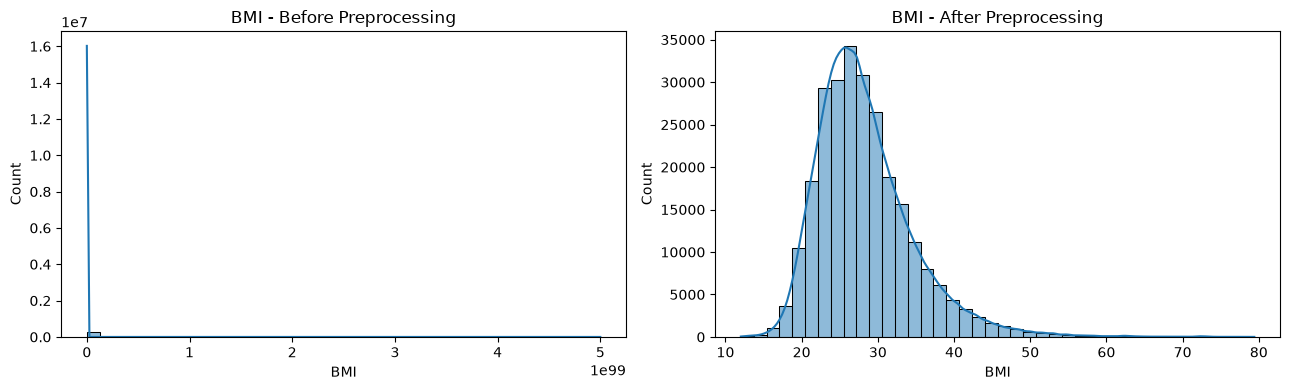

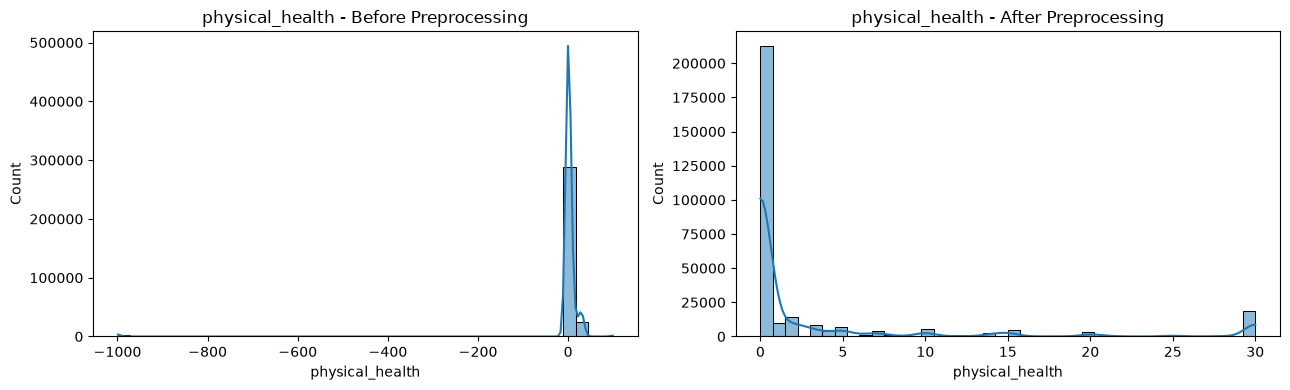

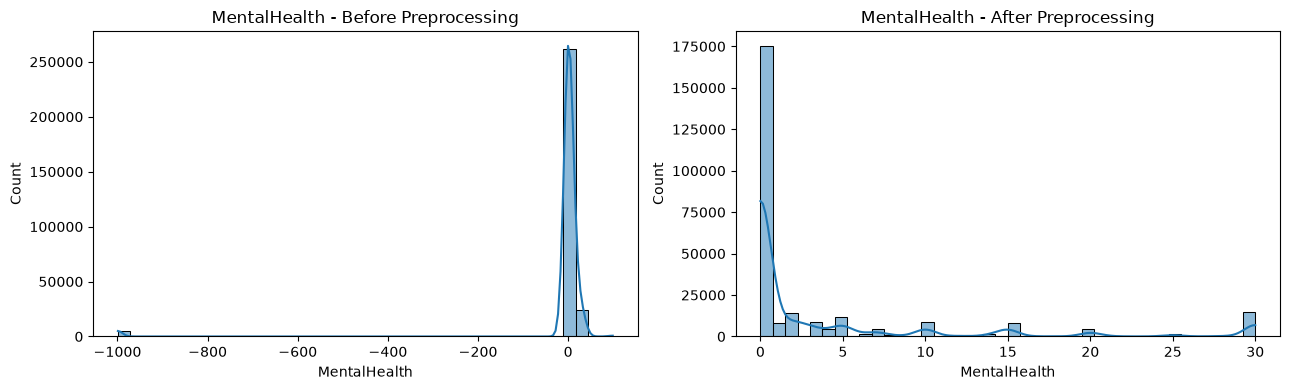

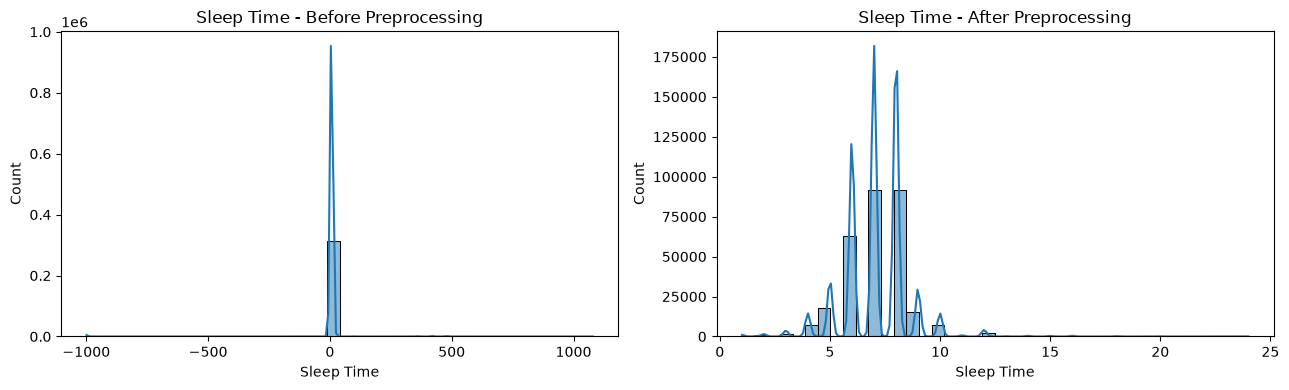

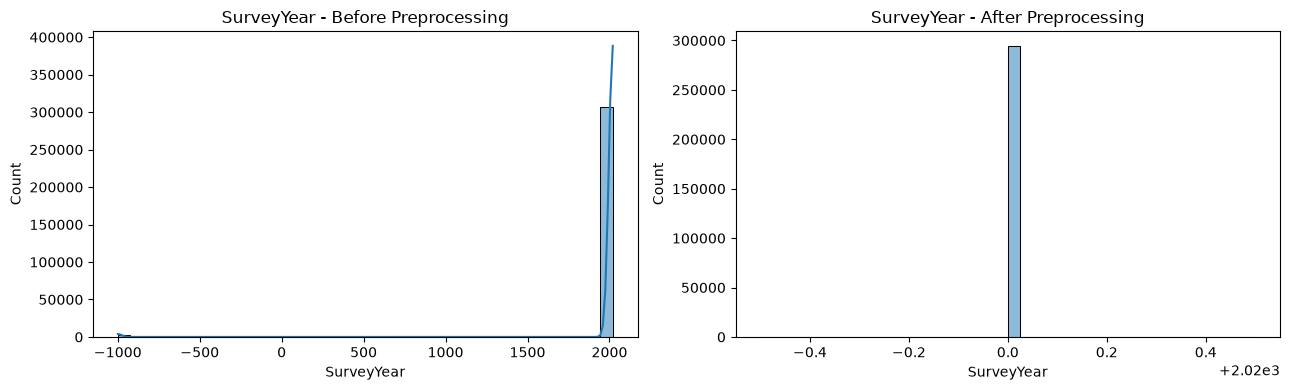

In [84]:
# Numeric columns available in both datasets
numeric_compare_cols = [
    col for col in [
        'BMI',
        'physical_health',
        'MentalHealth',
        'Sleep Time',
        'HealthBurden',
        'ChronicConditionCount',
        'LifestyleScore',
        'SurveyYear'
    ]
    if col in df_raw.columns and col in df_clean.columns
]

for col in numeric_compare_cols:

    before = pd.to_numeric(
        df_raw[col].astype('string').str.replace(',', '.', regex=False),
        errors='coerce'
    )

    after = pd.to_numeric(
        df_clean[col],
        errors='coerce'
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    sns.histplot(
        before.dropna(),
        bins=40,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f'{col} - Before Preprocessing')
    axes[0].set_xlabel(col)

    sns.histplot(
        after.dropna(),
        bins=40,
        kde=True,
        ax=axes[1]
    )

    axes[1].set_title(f'{col} - After Preprocessing')
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

باکس پلات داده های عددی بعد پردازش ها

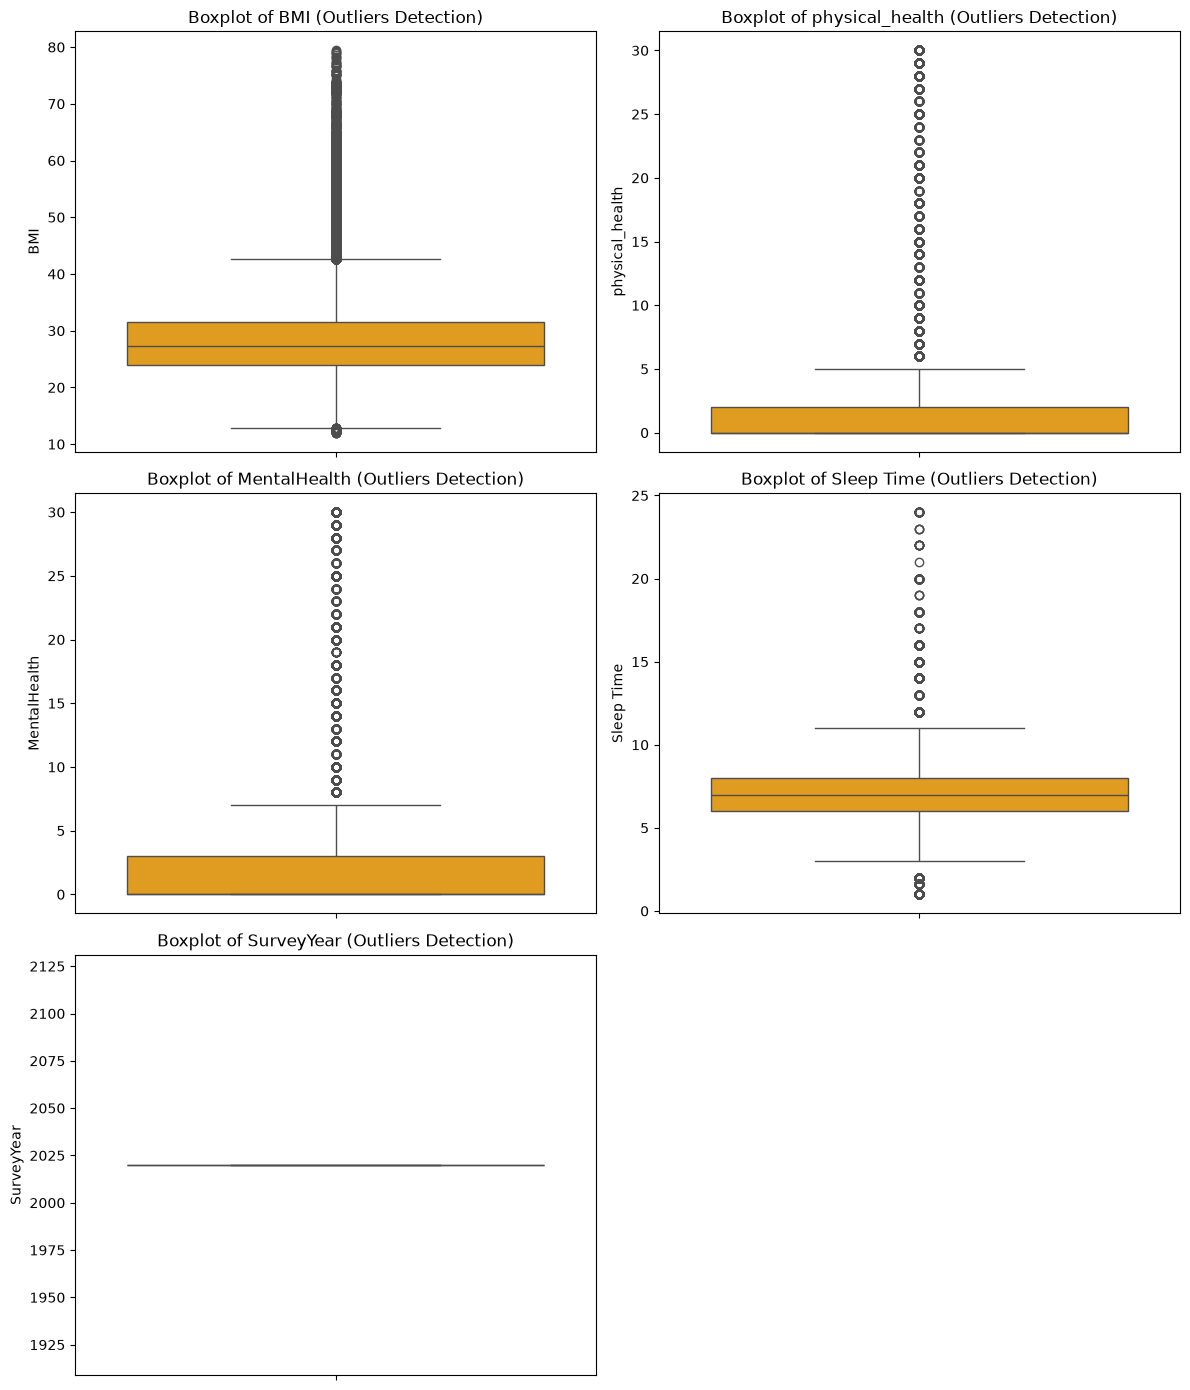

In [85]:

#  Boxplots for Numeric Columns (Outlier detection visual)
# تنظیم شبکه ۳ در ۲ برای باکس‌پلات‌ها
fig, axes = plt.subplots(3, 2, figsize=(12, 14))
axes = axes.flatten()

for i, col in enumerate(NumericCols):
    ax = axes[i]
    data_clean = df_clean[col].dropna()
    
    sns.boxplot(y=data_clean, ax=ax, color='orange')
    ax.set_title(f'Boxplot of {col} (Outliers Detection)')
    ax.set_ylabel(col)

if len(NumericCols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

۳-۲. مقایسه ویژگی‌های دسته‌ای

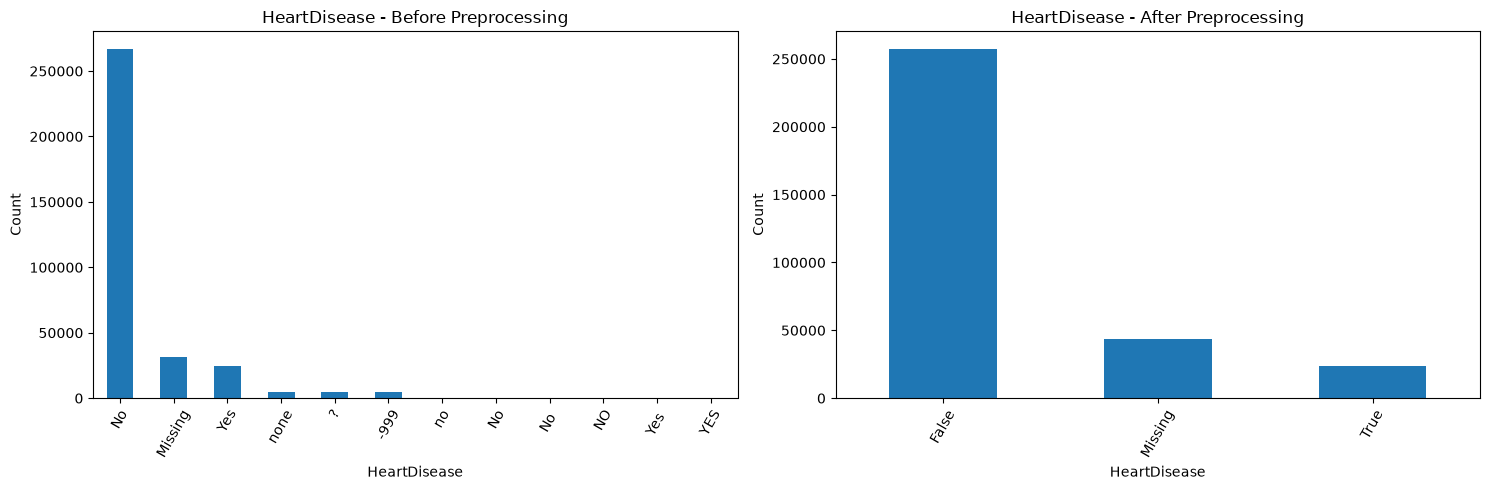

C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\1256059756.py:59: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


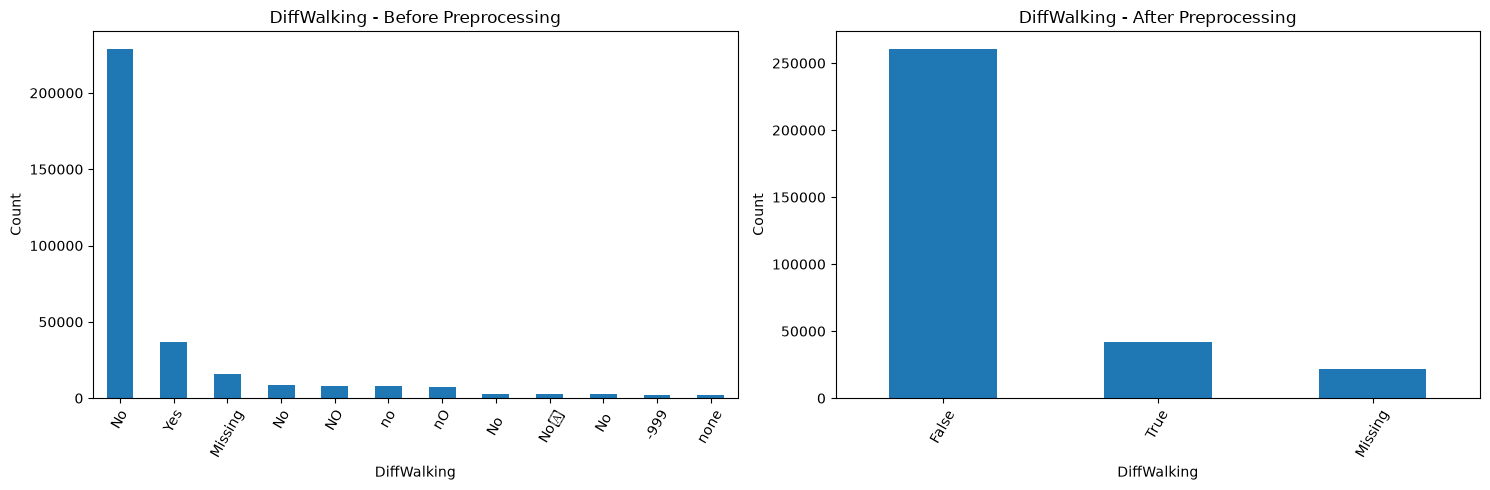

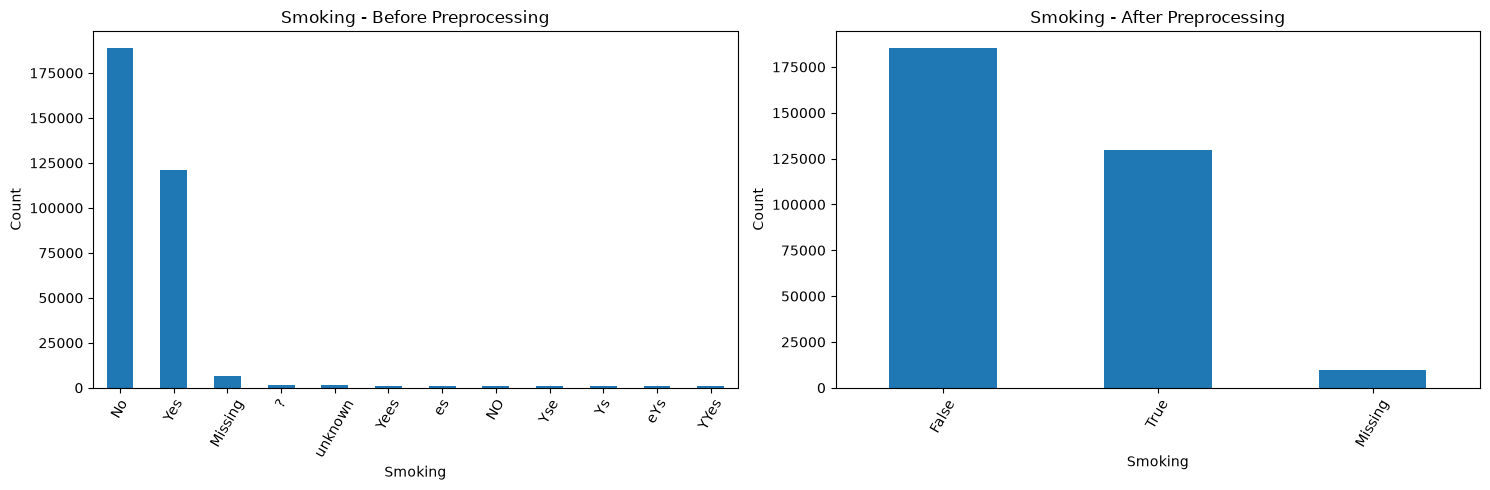

C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\1256059756.py:59: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


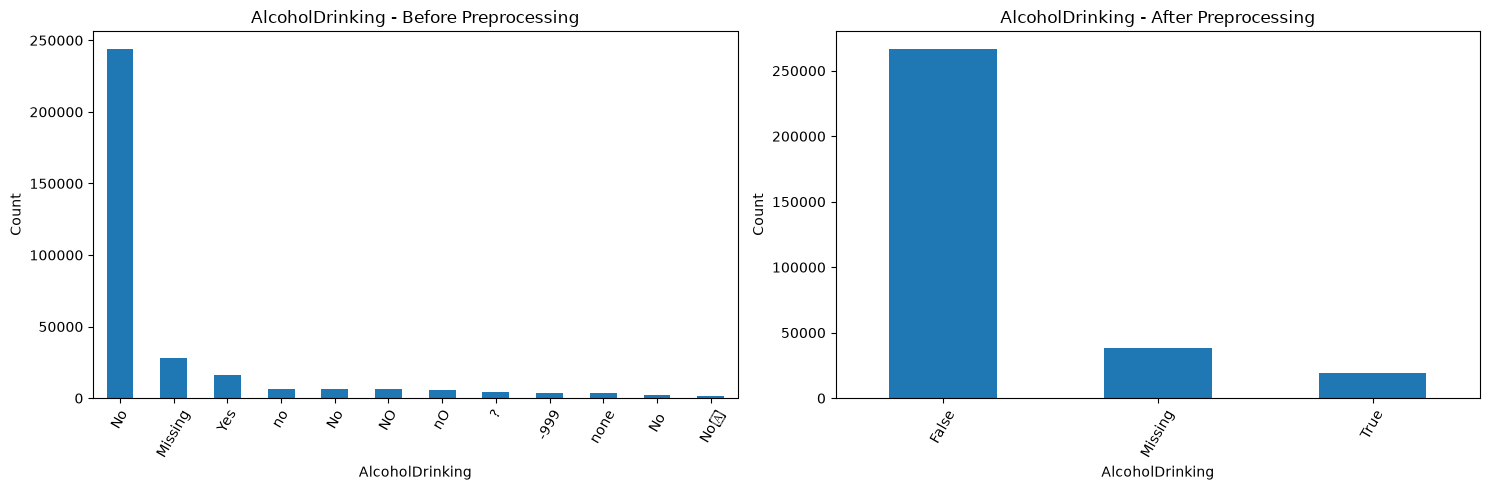

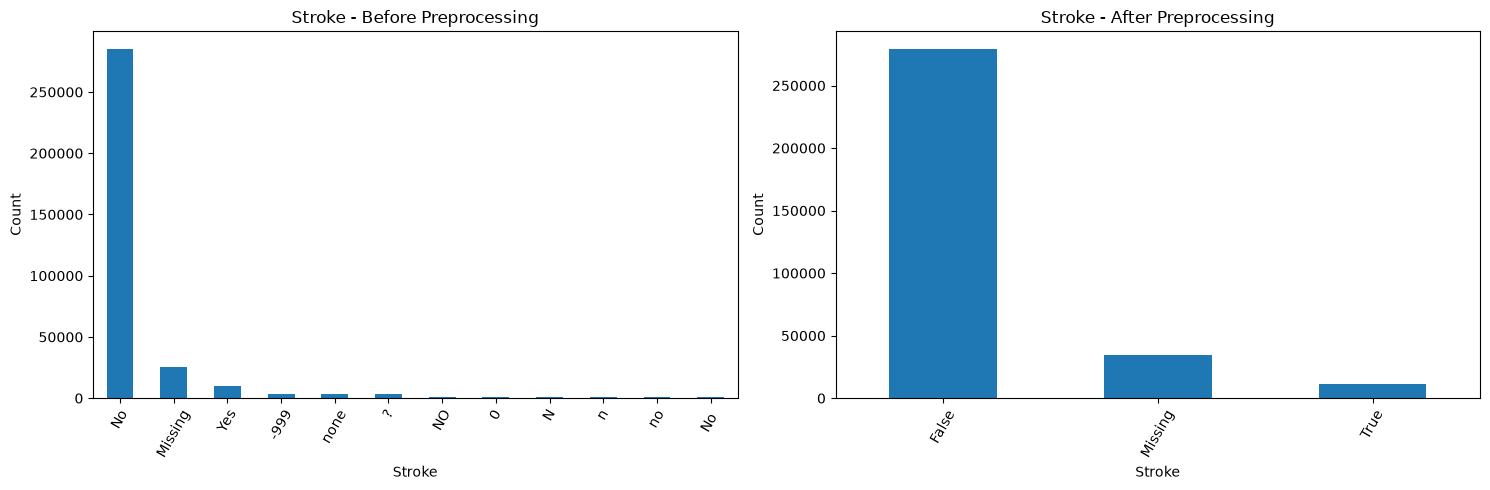

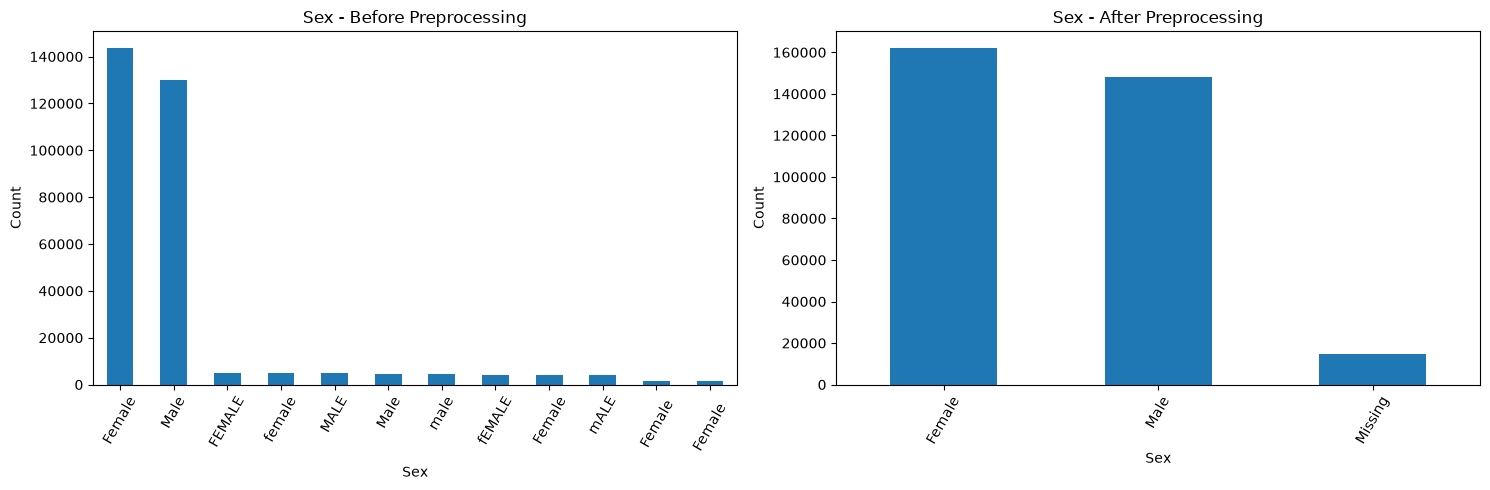

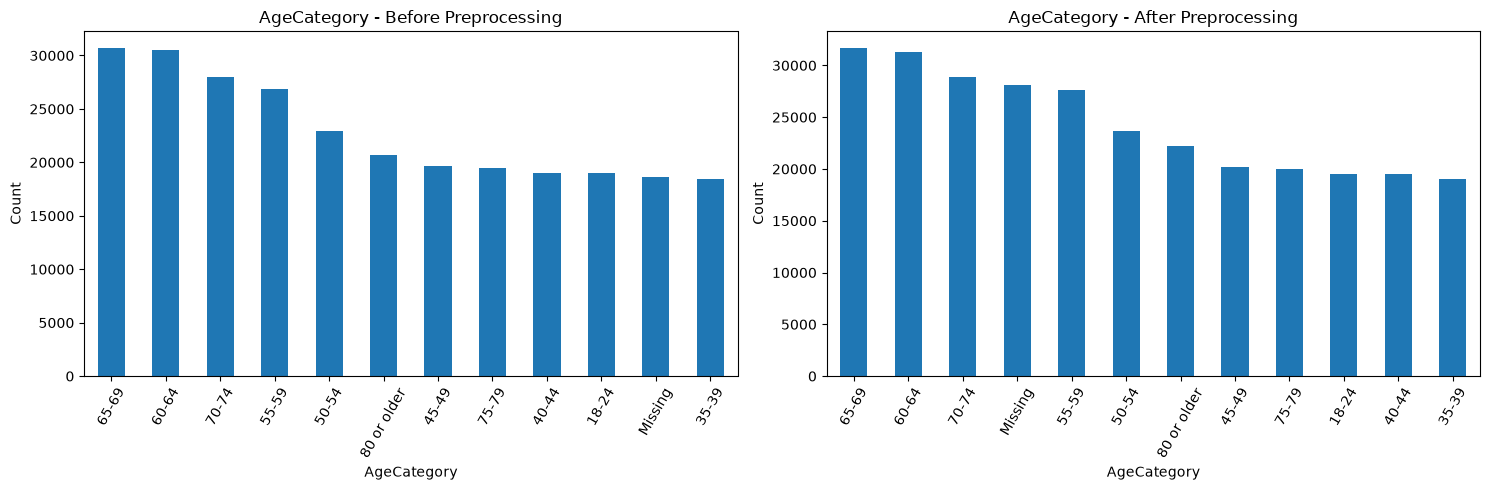

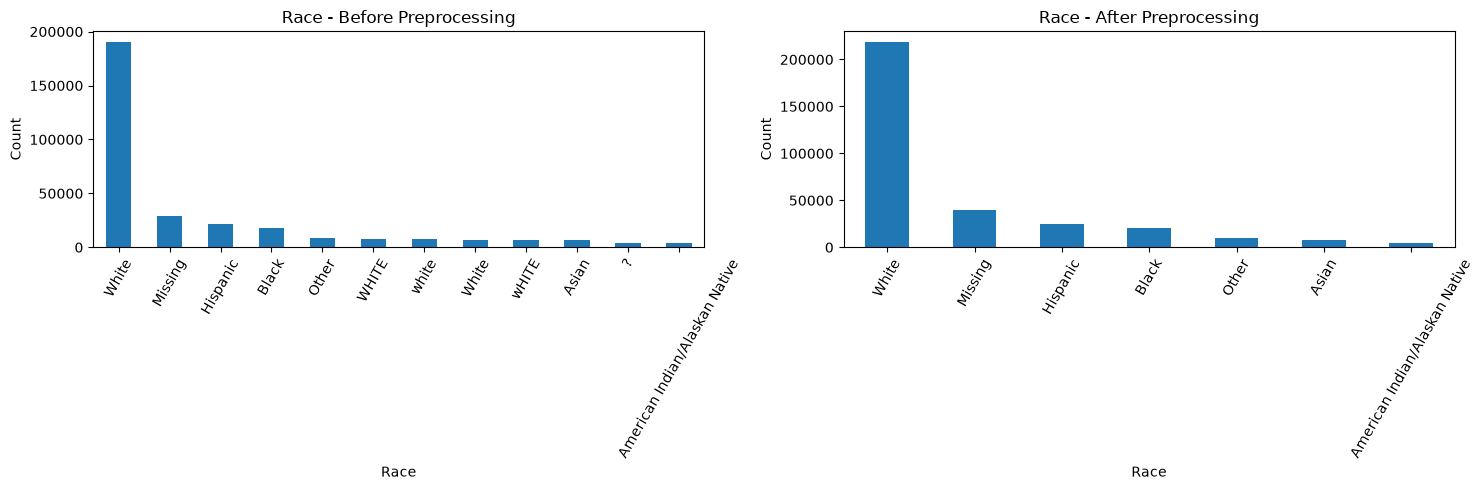

C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\1256059756.py:59: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


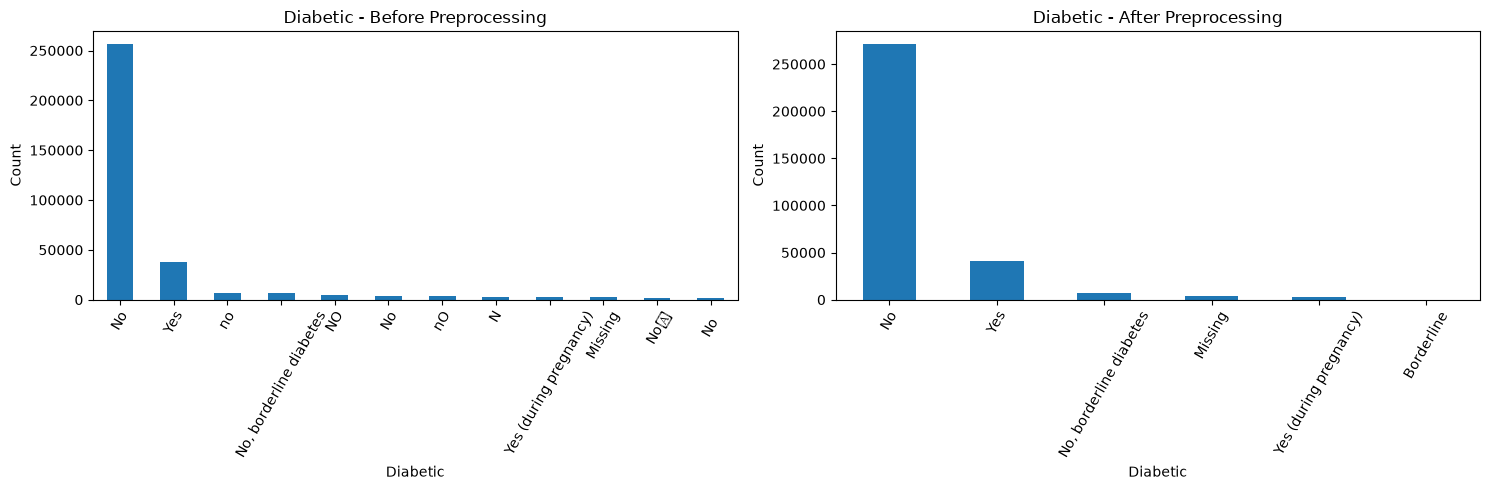

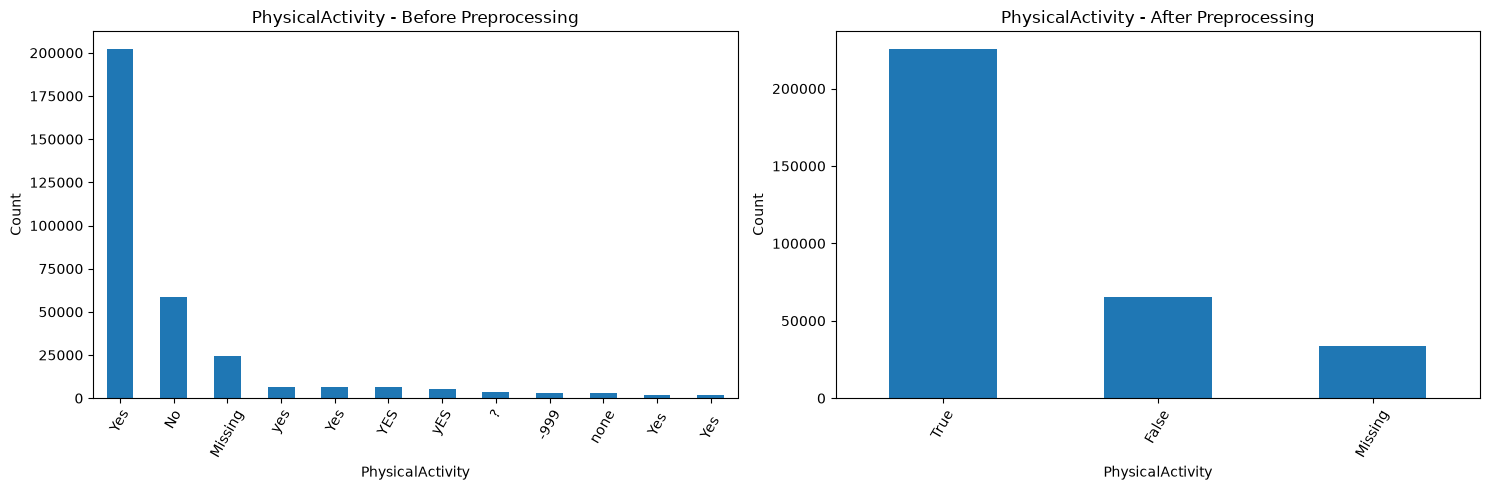

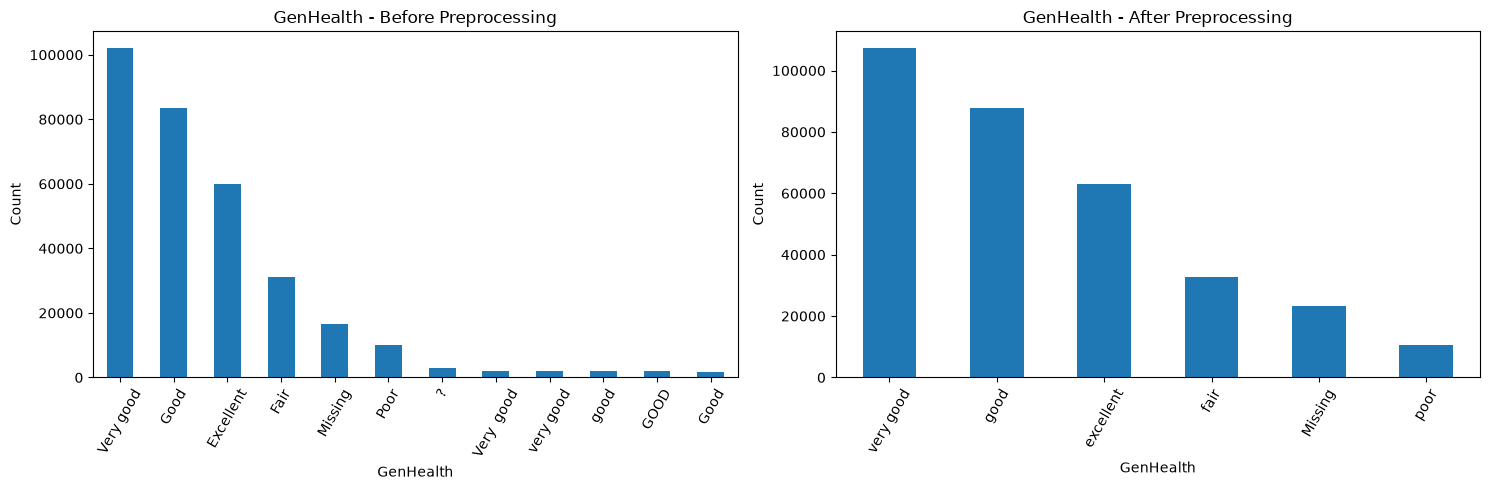

C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\1256059756.py:59: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


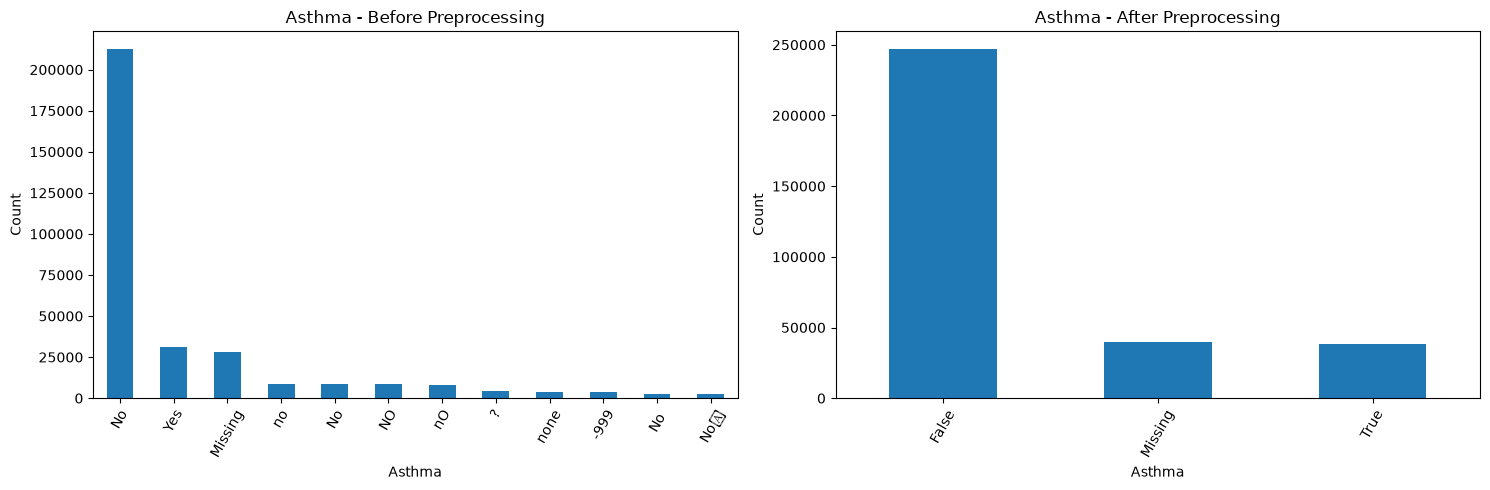

C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\1256059756.py:59: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


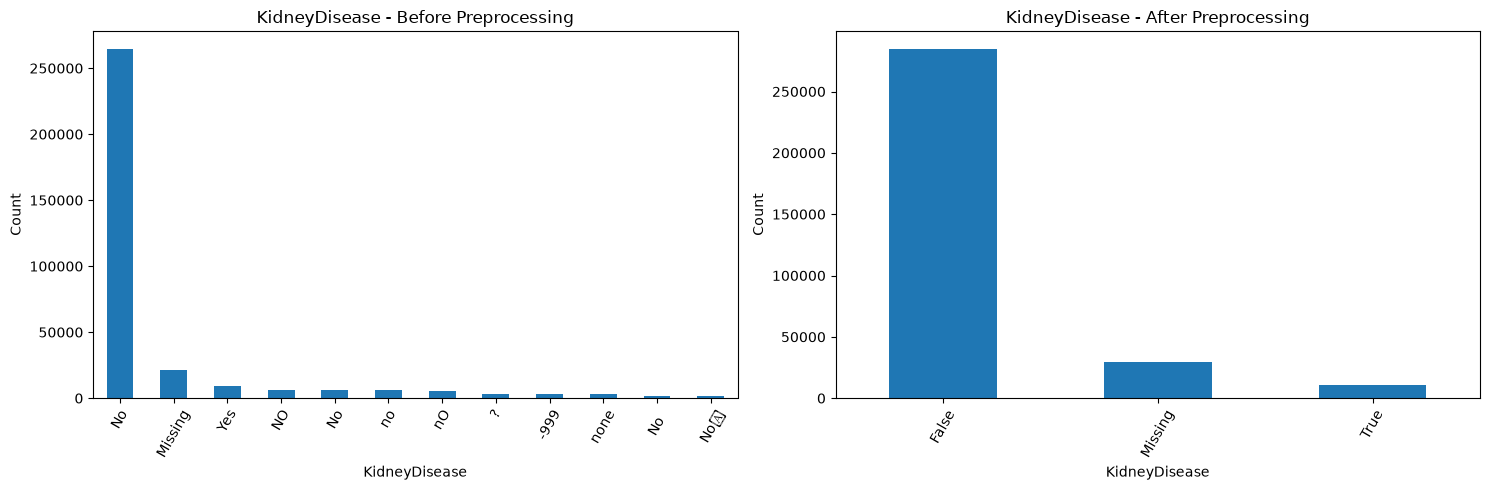

C:\Users\IRAN\AppData\Local\Temp\ipykernel_8024\1256059756.py:59: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\Python 3.12.9\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


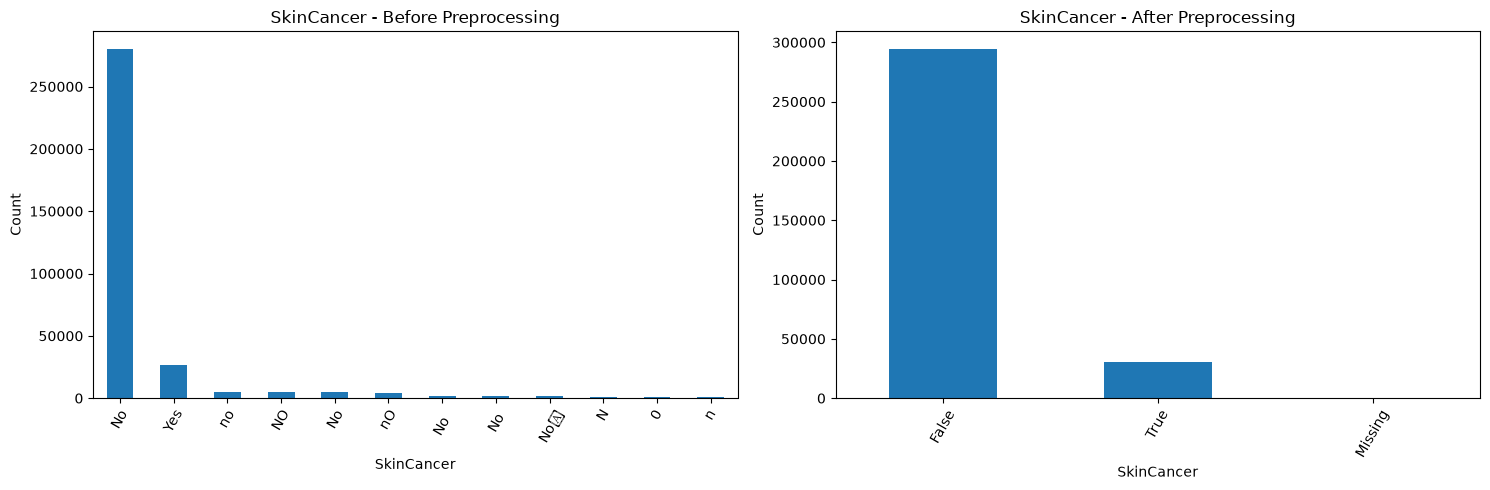

In [86]:
categorical_compare_cols = [
    col for col in [
        'HeartDisease',
        'DiffWalking',
        'Smoking',
        'AlcoholDrinking',
        'Stroke',
        'Sex',
        'AgeCategory',
        'Race',
        'Diabetic',
        'PhysicalActivity',
        'GenHealth',
        'Asthma',
        'KidneyDisease',
        'SkinCancer'
    ]
    if col in df_raw.columns and col in df_clean.columns
]

for col in categorical_compare_cols:

    before = (
        df_raw[col]
        .astype('string')
        .fillna('Missing')
        .value_counts()
        .head(12) # keeps only the 12 most frequent values.
    )

    after = (
        df_clean[col]
        .astype('string')
        .fillna('Missing')
        .value_counts()
        .head(12)
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    before.plot(
        kind='bar',
        ax=axes[0]
    )

    axes[0].set_title(f'{col} - Before Preprocessing')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=60)

    after.plot(
        kind='bar',
        ax=axes[1]
    )

    axes[1].set_title(f'{col} - After Preprocessing')
    axes[1].set_ylabel('Count')
    axes[1].tick_params(axis='x', rotation=60)

    plt.tight_layout()
    plt.show()

۳-۳. مقایسه Missing Values

,Before (%),After (%)
Comments,98.55,98.55
BMI,17.03,19.64
MentalHealth,14.16,16.03
HeartDisease,9.34,13.35
Race,8.45,12.12
SurveyYear,8.42,9.35
Asthma,8.39,12.17
AlcoholDrinking,8.28,11.91
Stroke,7.49,10.64
PhysicalActivity,7.23,10.36


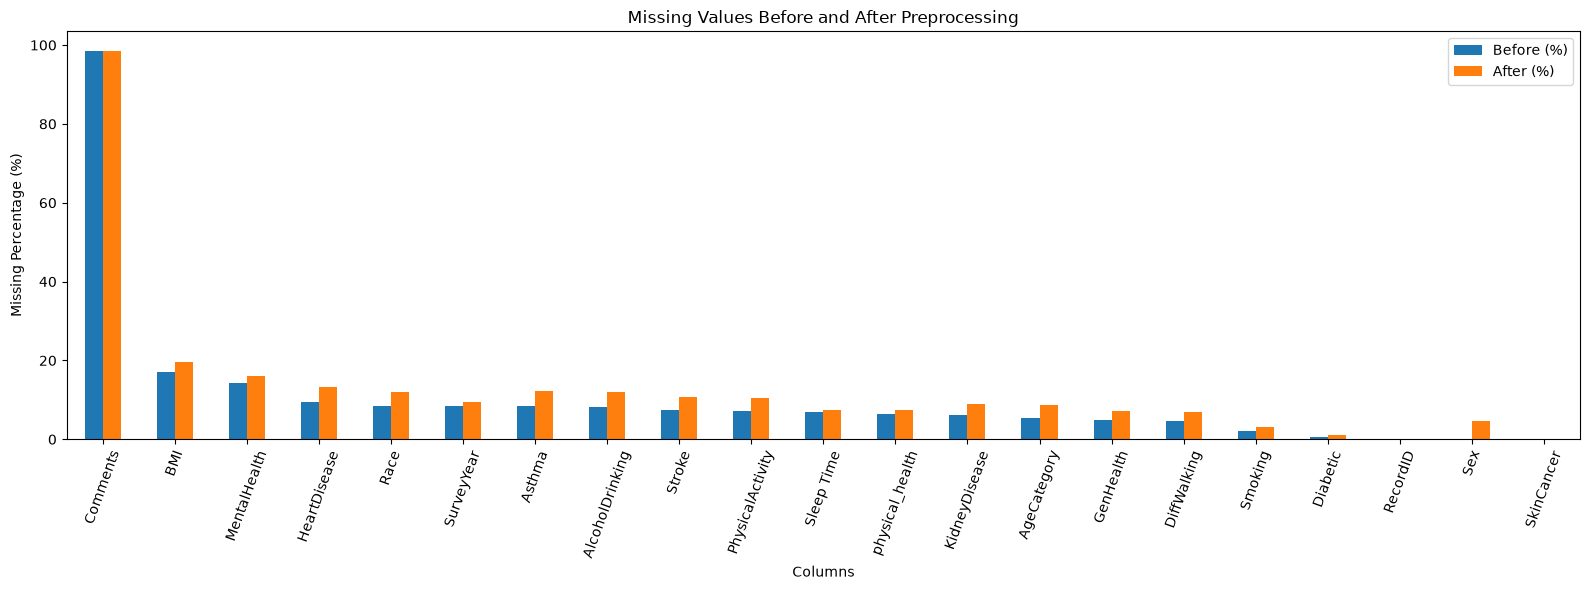

In [87]:
missing_before = (
    df_raw.isna().mean() * 100
).sort_values(ascending=False)

missing_after = (
    df_clean.isna().mean() * 100
).reindex(missing_before.index)

missing_comparison = pd.DataFrame({
    'Before (%)': missing_before,
    'After (%)': missing_after
})

display(missing_comparison.round(2))

missing_comparison.plot(
    kind='bar',
    figsize=(16, 6)
)

plt.title('Missing Values Before and After Preprocessing')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Columns')
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

آماده‌سازی داده برای PCA، Kernel PCA و SNE

برای اجرای این الگوریتم‌ها باید داده‌ها عددی و مقیاس‌بندی شده باشند.

در این قسمت:
- ویژگی‌های اسمی با One-Hot Encoding تبدیل می‌شوند.
- ویژگی‌های بولی به ۰ و ۱ تبدیل می‌شوند.
- ویژگی‌های عددی استاندارد می‌شوند.
- ستون هدف HeartDisease از ورودی الگوریتم‌های کاهش ابعاد کنار گذاشته می‌شود تا اطلاعات هدف وارد فرایند کاهش ابعاد نشود.

In [88]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import KernelPCA
from sklearn.manifold import TSNE

# Target variable
if 'HeartDisease' in df_model.columns:

    y = df_model['HeartDisease'].astype(int)

    X = df_model.drop(
        columns=['HeartDisease']
    ).copy()

else:
    y = None
    X = df_model.copy()


# Convert boolean columns to integer
for col in X.select_dtypes(
    include=['bool', 'boolean']
).columns:

    X[col] = X[col].astype(int)


# One-Hot Encoding for categorical variables
X_encoded = pd.get_dummies(
    X,
    drop_first=False,
    dtype=int
)

# Ensure all columns are numeric
X_encoded = X_encoded.astype(float)

# Standardization
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_encoded)

print("Encoded data shape:", X_encoded.shape)
print("Scaled data shape:", X_scaled.shape)

Encoded data shape: (324913, 46)
Scaled data shape: (324913, 46)


اجرای PCA

PCA با هدف یافتن ترکیب‌های خطی از ویژگی‌ها اجرا می‌شود. در این روش مؤلفه‌هایی انتخاب می‌شوند که بیشترین میزان واریانس داده‌ها را توضیح می‌دهند.

Explained variance ratio:
[0.08625177 0.0510259 ]
Total explained variance: 0.13727766701887914


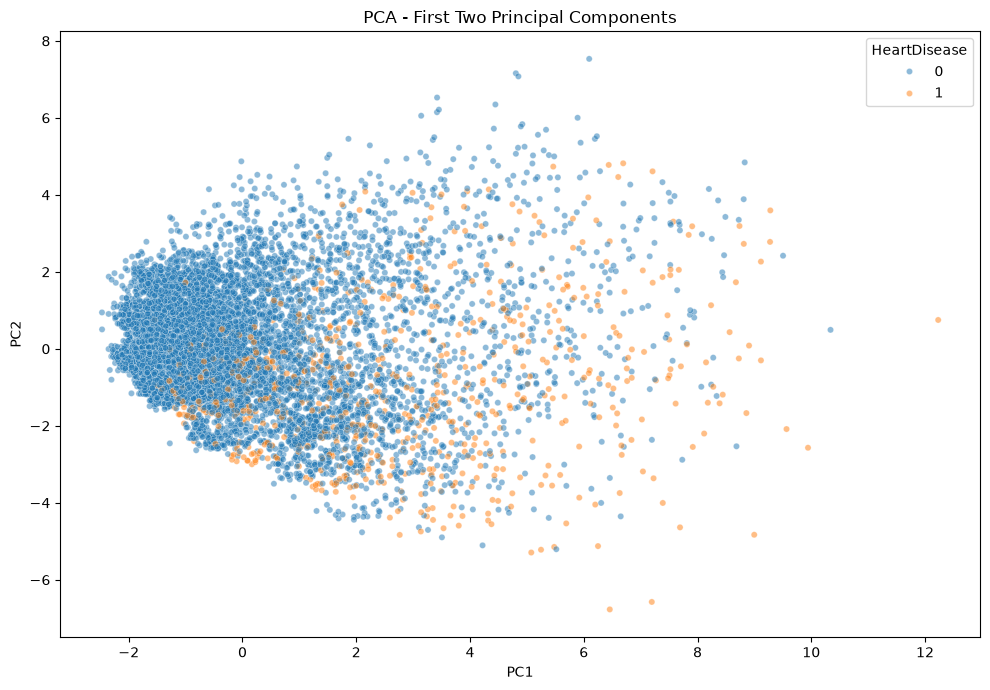

In [89]:
# PCA with two components
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

# Create DataFrame for visualization
pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1]
})

if y is not None:
    pca_df['HeartDisease'] = y.values


plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df.sample(
        min(10000, len(pca_df)),
        random_state=42
    ),
    x='PC1',
    y='PC2',
    hue='HeartDisease' if y is not None else None,
    alpha=0.5,
    s=20
)

plt.title('PCA - First Two Principal Components')
plt.tight_layout()
plt.show()

 اجرای Kernel PCA
 
در PCA معمولی، تبدیل داده‌ها خطی است. اما Kernel PCA با استفاده از Kernel Trick می‌تواند ساختارهای غیرخطی را نیز بررسی کند.

با توجه به حجم دیتاست، Kernel PCA را روی یک نمونه تصادفی از داده‌ها اجرا می‌کنیم؛ اجرای آن روی کل ۳۱۸ هزار رکورد می‌تواند بسیار پرهزینه و زمان‌بر باشد.

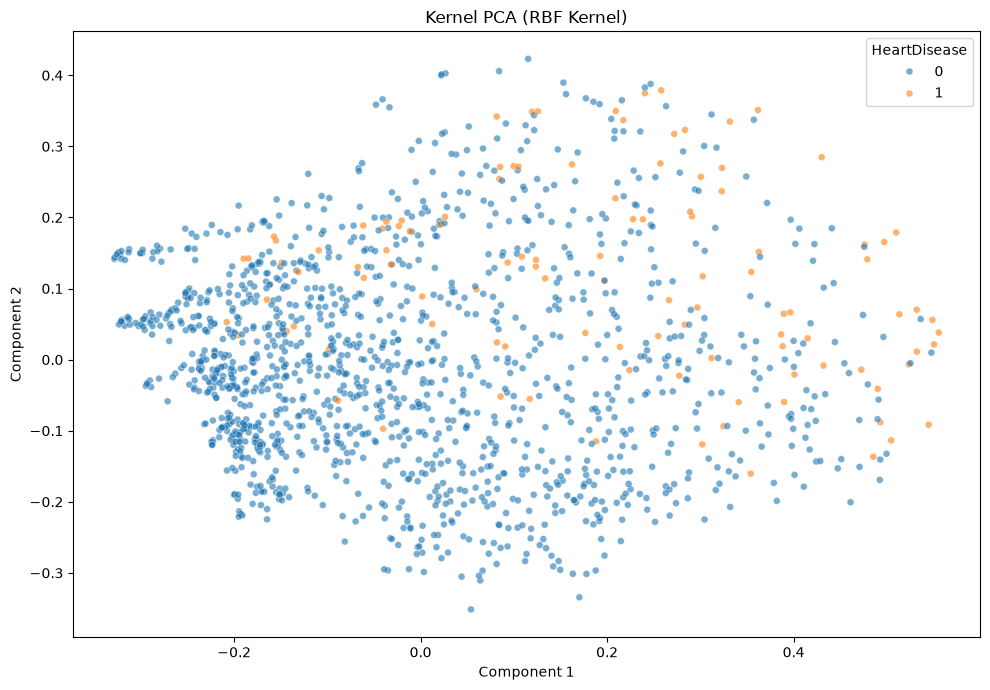

In [ ]:
# Sample for Kernel PCA
kpca_sample_size = min(1500, len(X_scaled))

rng = np.random.RandomState(42)

kpca_indices = rng.choice(
    len(X_scaled),
    size=kpca_sample_size,
    replace=False
)

X_kpca_sample = X_scaled[kpca_indices]

if y is not None:
    y_kpca = y.iloc[kpca_indices].values


# Kernel PCA using RBF kernel
kpca = KernelPCA(
    n_components=2, #Reduce data to 2 dimensions
    kernel='rbf',
    gamma=0.01,
    eigen_solver='arpack',#which numerical algorithm to use to calculate eigenvalues and eigenvectors.
    random_state=42
)

X_kpca = kpca.fit_transform(X_kpca_sample)

kpca_df = pd.DataFrame({
    'Component 1': X_kpca[:, 0],
    'Component 2': X_kpca[:, 1]
})

if y is not None:
    kpca_df['HeartDisease'] = y_kpca


plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=kpca_df,
    x='Component 1',
    y='Component 2',
    hue='HeartDisease' if y is not None else None,
    alpha=0.6,
    s=25
)

plt.title('Kernel PCA (RBF Kernel)')
plt.tight_layout()
plt.show()

اجرای SNE یا t-SNE

 از t-SNE

  استفاده می‌کنیم که یکی از روش‌های مبتنی بر 
  
  SNE 

  برای کاهش ابعاد غیرخطی است. این الگوریتم تلاش می‌کند همسایگی نمونه‌ها را در فضای دوبعدی حفظ کند.

به دلیل هزینه محاسباتی بالا، آن را روی نمونه‌ای از داده‌ها اجرا می‌کنیم.

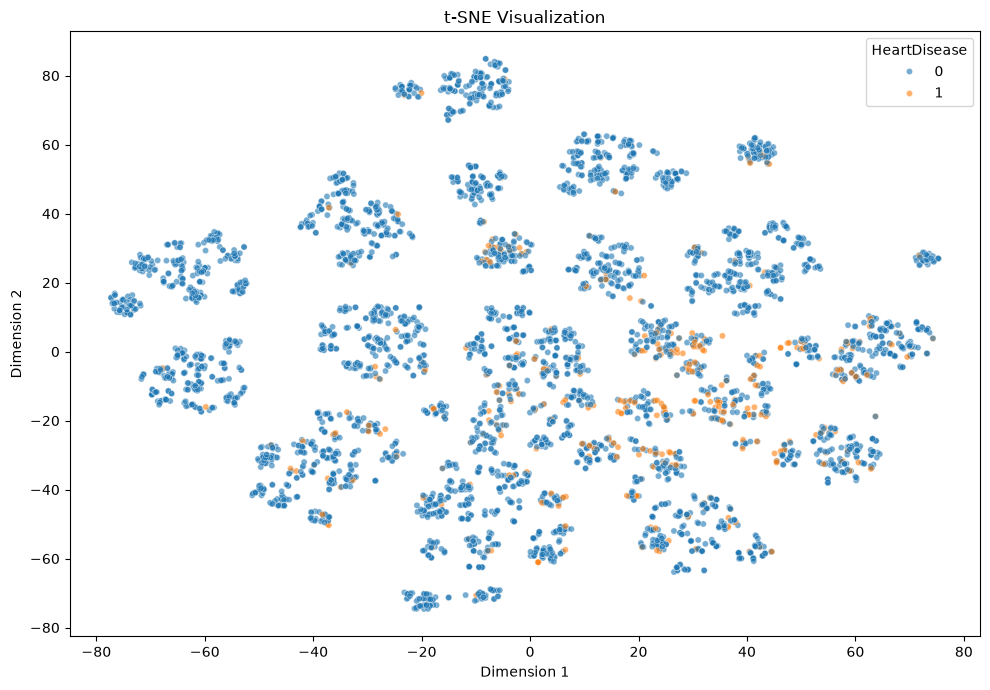

In [ ]:
# Sample for t-SNE
tsne_sample_size = min(5000, len(X_scaled))

tsne_indices = rng.choice(
    len(X_scaled),
    size=tsne_sample_size,
    replace=False
)

X_tsne_sample = X_scaled[tsne_indices]

if y is not None:
    y_tsne = y.iloc[tsne_indices].values

# t-SNE tries to arrange data points in 2D so that similar points stay close together.
tsne = TSNE(
    n_components=2,
    perplexity=30, #effective number of neighbors considered around each point
    learning_rate='auto',
    init='pca', #Initializes the embedding using PCA coordinates, determines how the points are positioned at the very beginning of the algorithm
    max_iter=1000,
    random_state=42 #Makes the randomized process reproducible
)

X_tsne = tsne.fit_transform(X_tsne_sample)

tsne_df = pd.DataFrame({
    'Dimension 1': X_tsne[:, 0],
    'Dimension 2': X_tsne[:, 1]
})

if y is not None:
    tsne_df['HeartDisease'] = y_tsne


plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x='Dimension 1',
    y='Dimension 2',
    hue='HeartDisease' if y is not None else None,
    alpha=0.6,
    s=20
)

plt.title('t-SNE Visualization')
plt.tight_layout()
plt.show()

مقایسه سه روش کاهش ابعاد

در این قسمت سه نمودار را کنار هم قرار می‌دهیم.

Kernel PCA و t-SNE روی نمونه‌های متفاوت یا با روش‌های تبدیل متفاوت اجرا شده‌اند؛ بنابراین مقایسه بصری آن‌ها مقایسه‌ای کیفی است، نه مقایسه مستقیم مختصات.

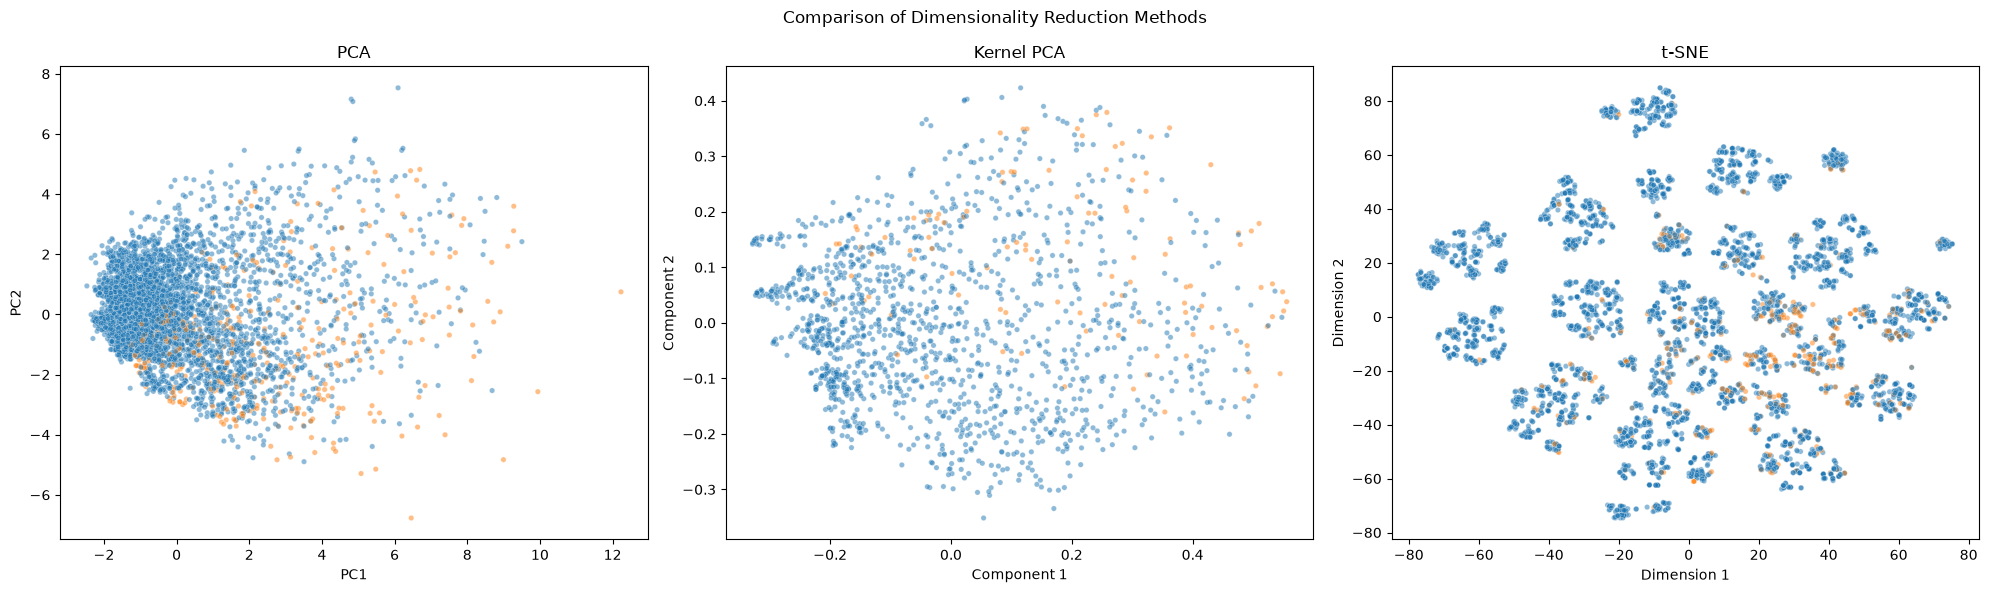

In [92]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# PCA
sns.scatterplot(
    data=pca_df.sample(
        min(5000, len(pca_df)),
        random_state=42
    ),
    x='PC1',
    y='PC2',
    hue='HeartDisease' if y is not None else None,
    alpha=0.5,
    s=15,
    ax=axes[0],
    legend=False
)

axes[0].set_title('PCA')


# Kernel PCA
sns.scatterplot(
    data=kpca_df,
    x='Component 1',
    y='Component 2',
    hue='HeartDisease' if y is not None else None,
    alpha=0.5,
    s=15,
    ax=axes[1],
    legend=False
)

axes[1].set_title('Kernel PCA')


# t-SNE
sns.scatterplot(
    data=tsne_df,
    x='Dimension 1',
    y='Dimension 2',
    hue='HeartDisease' if y is not None else None,
    alpha=0.5,
    s=15,
    ax=axes[2],
    legend=False
)

axes[2].set_title('t-SNE')

plt.suptitle('Comparison of Dimensionality Reduction Methods')
plt.tight_layout()
plt.show()

In [93]:
# Save cleaned dataset
df_clean.to_csv(
    'HeartDisease_cleaned.csv',
    index=False
)

# Save PCA results
pca_df.to_csv(
    'HeartDisease_PCA.csv',
    index=False
)

# Save Kernel PCA results
kpca_df.to_csv(
    'HeartDisease_KernelPCA.csv',
    index=False
)

# Save t-SNE results
tsne_df.to_csv(
    'HeartDisease_tSNE.csv',
    index=False
)

print("All files saved successfully.")

All files saved successfully.


## Smoking ↔ HeartDisease (Chi-Square)

In [104]:
from scipy.stats import chi2_contingency
from scipy.stats import chi2 as chi2_lib

# Select the two variables
data = df_clean[['Smoking', 'HeartDisease']].dropna()

# Create contingency table
contingency_table = pd.crosstab(
    data['Smoking'],
    data['HeartDisease']
)

print("Contingency Table:")
print(contingency_table)

# Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected Frequencies:")
print(expected_df.round(2))

print("\nChi-Square Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print("P-value:", p_value)
print(f"Degrees of freedom: {dof}")

# Interpretation
alpha = 0.05

if p_value < alpha:
    print("\nConclusion: There is a statistically significant association")
    print("between Smoking and HeartDisease.")
else:
    print("\nConclusion: No statistically significant association was found")
    print("between Smoking and HeartDisease.")

# # Cramer's V: strength of association
# n = contingency_table.to_numpy().sum()
# cramers_v = np.sqrt(chi2 / n)

# print(f"\nCramer's V: {cramers_v:.4f}")

Contingency Table:
HeartDisease   False  True 
Smoking                    
False         150850   9624
True           98840  13727

Expected Frequencies:
HeartDisease      False     True 
Smoking                          
False         146749.95  13724.05
True          102940.05   9626.95

Chi-Square Results:
Chi-square statistic: 3248.1315
P-value: 0.0
Degrees of freedom: 1

Conclusion: There is a statistically significant association
between Smoking and HeartDisease.


## check if SurveyYear actualy is least important as I thought

In [114]:
from sklearn.metrics import mutual_info_score

# ==========================================
# 1. Select original columns only
# ==========================================

original_columns = [
    'HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking',
    'Stroke', 'physical_health', 'MentalHealth', 'DiffWalking',
    'Sex', 'AgeCategory', 'Race', 'Diabetic', 'PhysicalActivity',
    'GenHealth', 'Sleep Time', 'Asthma', 'KidneyDisease',
    'SkinCancer', 'SurveyYear', 'Comments'
]

data = df_clean[original_columns].copy()

# ==========================================
# 2. Separate target and features
# ==========================================

target = data['HeartDisease']
features = data.drop(columns=['HeartDisease', 'RecordID'], errors='ignore')

# Remove rows where target is missing
valid_idx = target.notna()
target = target.loc[valid_idx].astype('string')
features = features.loc[valid_idx].copy()

# ==========================================
# 3. Discretize continuous numerical features
# ==========================================

continuous_cols = [
    'BMI',
    'physical_health',
    'MentalHealth',
    'Sleep Time'
]

for col in continuous_cols:

    if col in features.columns and features[col].nunique(dropna=True) > 1:

        features[col] = pd.qcut(
            features[col],
            q=10,
            duplicates='drop'
        )

# Treat missing values as a separate category
features = features.astype('string').fillna('Missing')

# ==========================================
# 4. Calculate Information Gain (in bits)
# ==========================================

results = []

H_target = -np.sum(
    target.value_counts(normalize=True) *
    np.log2(target.value_counts(normalize=True))
)

for col in features.columns:

    # Mutual Information = Information Gain
    IG = mutual_info_score(
        features[col],
        target
    ) / np.log(2)

    # Conditional entropy
    H_cond = H_target - IG

    results.append({
        'Feature': col,
        'Information Gain (bits)': IG,
        'Conditional Entropy (bits)': H_cond
    })

# ==========================================
# 5. Sort from least to most informative
# ==========================================

ig_df = pd.DataFrame(results)

ig_df = ig_df.sort_values(
    'Information Gain (bits)',
    ascending=True
).reset_index(drop=True)

display(ig_df.round(4))

,Feature,Information Gain (bits),Conditional Entropy (bits)
0,SurveyYear,0.0000,0.4214
1,Comments,0.0000,0.4213
2,AlcoholDrinking,0.0007,0.4206
3,MentalHealth,0.0010,0.4203
4,Asthma,0.0011,0.4203
5,Race,0.0020,0.4193
6,BMI,0.0022,0.4192
7,Sleep Time,0.0027,0.4187
8,Sex,0.0036,0.4178
9,SkinCancer,0.0052,0.4162
